In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from matplotlib.ticker import AutoMinorLocator

BASE = Path("/home/camaral/inct_cq_hybrid_nn/runs/pinn")

PASTA_MLP = BASE / "mlp_depth_2706/results/burgers/pinn_mlp_depth_4"
PASTA_MPC = BASE / "mpc_serial"

CORES = {
    "MLP": "#000000",
    "MPC": "#C00000",
}

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "mathtext.fontset": "cm",
    "axes.linewidth": 1.0,
    "axes.edgecolor": "black",
    "axes.spines.top": True,
    "axes.spines.right": True,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
    "legend.frameon": False,
    "figure.dpi": 130,
    "savefig.dpi": 300,
})

In [2]:
def carregar_resultados(arquivos):
    metricas = []
    historicos = []

    for arquivo in sorted(arquivos):
        with open(arquivo) as f:
            m = json.load(f)

        seed = int(arquivo.parent.name.split("_")[-1])

        m["seed"] = seed
        m["arquivo"] = str(arquivo)
        metricas.append(m)

        h = pd.read_csv(arquivo.parent / "history.csv")
        h["seed"] = seed
        h["arquivo"] = str(arquivo)
        historicos.append(h)

    return (
        pd.DataFrame(metricas),
        pd.concat(historicos, ignore_index=True)
    )


# MLP convencional
metricas_mlp, hist_mlp = carregar_resultados(
    PASTA_MLP.glob("seed_*/metrics.json")
)

# MPC quântico: 5 qubits, 3 camadas, Z, polinomial
metricas_mpc, hist_mpc = carregar_resultados(
    PASTA_MPC.glob(
        "0*_*/q5_l3_z_polynomial/seed_*/metrics.json"
    )
)

# Remover registros repetidos entre etapas
metricas_mpc = metricas_mpc.drop_duplicates("seed")

hist_mpc = hist_mpc[
    hist_mpc["arquivo"].isin(metricas_mpc["arquivo"])
].copy()

print("MLP:", metricas_mlp["seed"].nunique(), "sementes")
print("MPC:", metricas_mpc["seed"].nunique(), "sementes")

MLP: 10 sementes
MPC: 10 sementes


In [3]:
hist_mlp["modelo"] = "MLP"
hist_mpc["modelo"] = "MPC"

historicos = pd.concat(
    [hist_mlp, hist_mpc],
    ignore_index=True
)

def plot_media_intervalo(ax, coluna, titulo, ylabel):
    for modelo in ["MLP", "MPC"]:
        dados = (
            historicos[historicos["modelo"] == modelo]
            .groupby("epoch")[coluna]
            .agg(["mean", "min", "max"])
            .reset_index()
        )

        x = dados["epoch"].to_numpy()

        ax.plot(
            x,
            dados["mean"].to_numpy(),
            color=CORES[modelo],
            linewidth=2.0,
            label=modelo
        )

        ax.fill_between(
            x,
            dados["min"].to_numpy(),
            dados["max"].to_numpy(),
            color=CORES[modelo],
            alpha=0.12,
            linewidth=0
        )

    #ax.set_title(titulo, pad=12)
    ax.set_xlabel("Epoch", fontsize=20)
    ax.set_ylabel(ylabel, fontsize=20)
    ax.set_yscale("log")
    ax.grid(True)
    ax.legend(loc="best")
    ax.tick_params(which="both", direction="in", top=True, right=True)

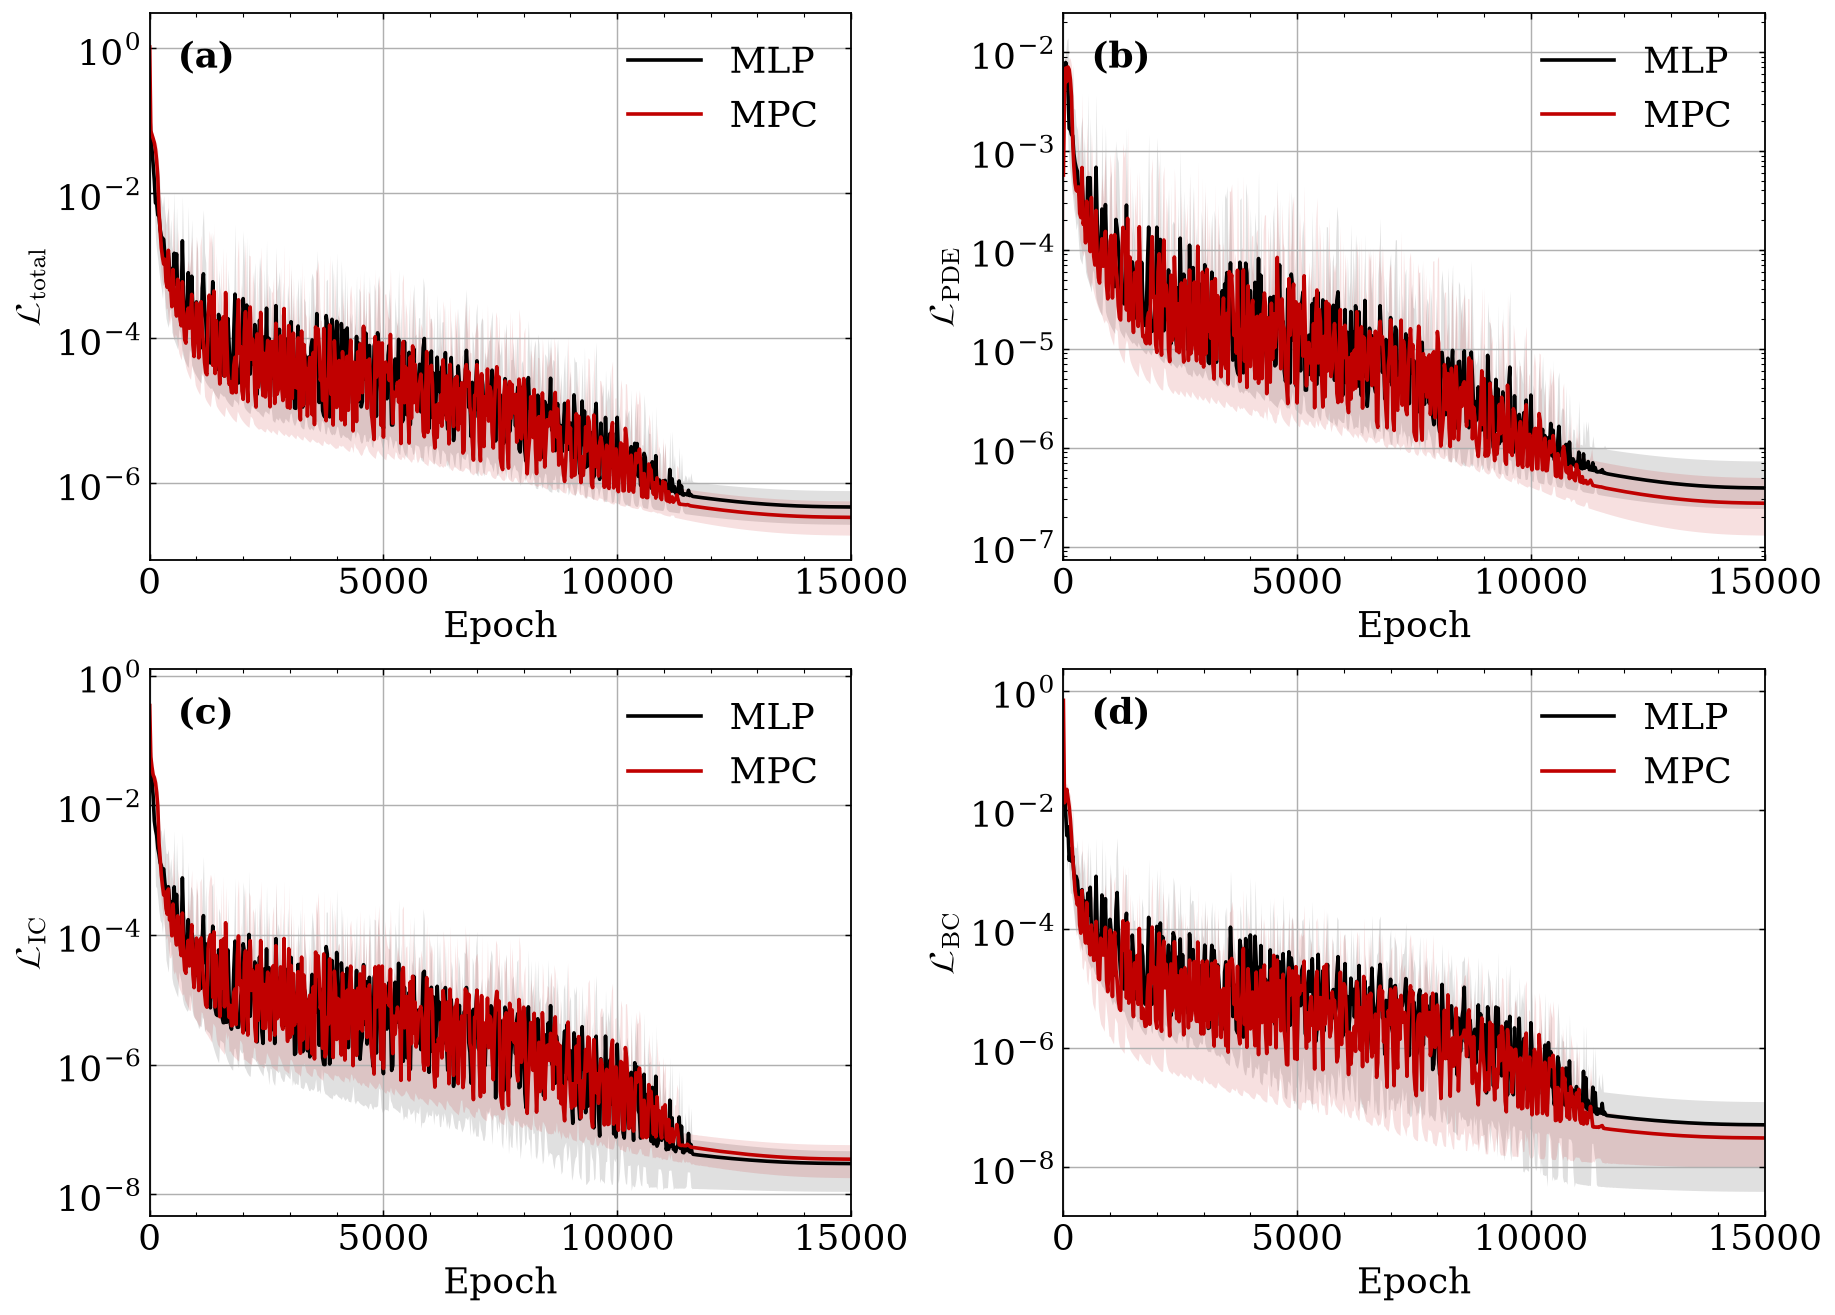

In [4]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10),
    constrained_layout=True
)

componentes = [
    ("train_mse", r"$\mathcal{L}_{\mathrm{total}}$"),
    ("loss_pde", r"$\mathcal{L}_{\mathrm{PDE}}$"),
    ("loss_ic", r"$\mathcal{L}_{\mathrm{IC}}$"),
    ("loss_bc", r"$\mathcal{L}_{\mathrm{BC}}$"),
]

letras = ["(a)", "(b)", "(c)", "(d)"]

for ax, (coluna, ylabel), letra in zip(
    axes.flat, componentes, letras
):

    plot_media_intervalo(
        ax,
        coluna,
        "",
        ylabel
    )

    # Identificação do painel
    ax.text(
        0.04, 0.95,
        letra,
        transform=ax.transAxes,
        fontsize=20,
        fontweight="bold",
        va="top",
        ha="left"
    )

    # Eixos
    ax.set_xlim(0, 15000)
    ax.set_xticks([0, 5000, 10000, 15000])

    ax.set_xlabel("Epoch", fontsize=20)
    ax.set_ylabel(ylabel, fontsize=20)

    ax.tick_params(
        axis="both",
        which="both",
        direction="in",
        top=True,
        right=True,
        labelsize=20
    )

    # Legenda
    ax.legend(
        fontsize=20,
        frameon=False,
        loc="best"
    )

    ax.set_title("")
    ax.grid(True)
plt.savefig("../paper/figs/loss_main.png", dpi=300, bbox_inches="tight")
plt.show()

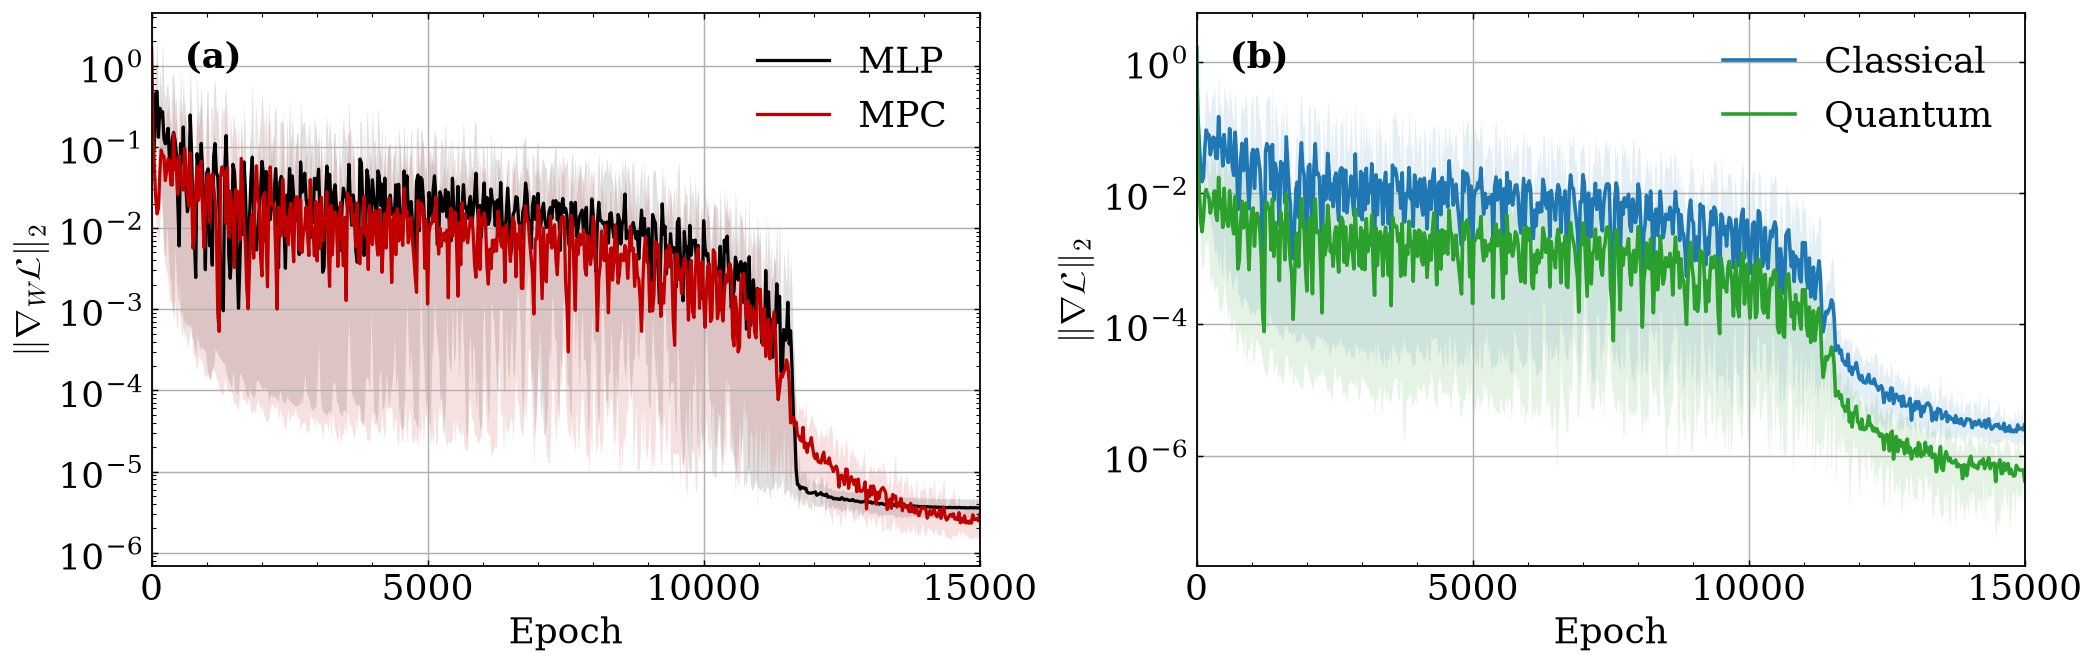

In [5]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 5),
    constrained_layout=True
)

# ==================================================
# (a) Gradientes clássicos: MLP vs MPC
# ==================================================

for modelo in ["MLP", "MPC"]:
    dados = (
        historicos[historicos["modelo"] == modelo]
        .groupby("epoch")["grad_classical"]
        .agg(["mean", "min", "max"])
        .reset_index()
    )

    axes[0].plot(
        dados["epoch"],
        dados["mean"],
        color=CORES[modelo],
        linewidth=1.8,
        label=modelo
    )

    axes[0].fill_between(
        dados["epoch"],
        dados["min"],
        dados["max"],
        color=CORES[modelo],
        alpha=0.12,
        linewidth=0
    )

axes[0].text(
    0.04, 0.95,
    "(a)",
    transform=axes[0].transAxes,
    fontsize=20,
    fontweight="bold",
    va="top",
    ha="left"
)

axes[0].set_xlim(0, 15000)
axes[0].set_xticks([0, 5000, 10000, 15000])
axes[0].set_xlabel("Epoch", fontsize=20)
axes[0].set_ylabel(r"$\|\nabla_{W}\mathcal{L}\|_2$", fontsize=20)
axes[0].set_yscale("log")
axes[0].legend(fontsize=20, frameon=False, loc="best")
axes[0].tick_params(
    axis="both",
    which="both",
    direction="in",
    top=True,
    right=True,
    labelsize=20
)
axes[0].grid(False)

# ==================================================
# (b) Gradientes do MPC: clássico vs quântico
# ==================================================

gradientes = {
    "Classical": ("grad_classical", "tab:blue"),
    "Quantum": ("grad_quantum", "tab:green"),
}

for nome, (coluna, cor) in gradientes.items():
    dados = (
        hist_mpc.groupby("epoch")[coluna]
        .agg(["mean", "min", "max"])
        .reset_index()
    )

    axes[1].plot(
        dados["epoch"],
        dados["mean"],
        color=cor,
        linewidth=2.0,
        label=nome
    )

    axes[1].fill_between(
        dados["epoch"],
        dados["min"],
        dados["max"],
        color=cor,
        alpha=0.12,
        linewidth=0
    )

axes[1].text(
    0.04, 0.95,
    "(b)",
    transform=axes[1].transAxes,
    fontsize=20,
    fontweight="bold",
    va="top",
    ha="left"
)

axes[1].set_xlim(0, 15000)
axes[1].set_xticks([0, 5000, 10000, 15000])
axes[1].set_xlabel("Epoch", fontsize=20)
axes[1].set_ylabel(r"$\|\nabla \mathcal{L}\|_2$", fontsize=20)
axes[1].set_yscale("log")
axes[1].legend(fontsize=20, frameon=False, loc="best")
axes[1].tick_params(
    axis="both",
    which="both",
    direction="in",
    top=True,
    right=True,
    labelsize=20
)
axes[0].grid(True)
axes[1].grid(True)


plt.savefig("../paper/figs/gradients_main.png", dpi=300, bbox_inches="tight")
plt.show()

In [6]:
metricas_mlp["modelo"] = "MLP"
metricas_mpc["modelo"] = "MPC"

metricas = pd.concat(
    [metricas_mlp, metricas_mpc],
    ignore_index=True
)

resumo = (
    metricas.groupby("modelo")
    .agg(
        sementes=("seed", "nunique"),
        rmse_medio=("rmse", "mean"),
        rmse_std=("rmse", "std"),
        mae_medio=("mae", "mean"),
        l2_relativo=("relative_l2", "mean"),
        parametros=("parameters", "first"),
    )
    .reset_index()
)

display(
    resumo.style.format({
        "rmse_medio": "{:.3e}",
        "rmse_std": "{:.3e}",
        "mae_medio": "{:.3e}",
        "l2_relativo": "{:.3e}",
    })
)

,modelo,sementes,rmse_medio,rmse_std,mae_medio,l2_relativo,parametros
0,MLP,10,9.326e-05,4.683e-05,5.310e-05,4.213e-04,3297
1,MPC,10,6.618e-05,1.141e-05,3.972e-05,2.989e-04,3459


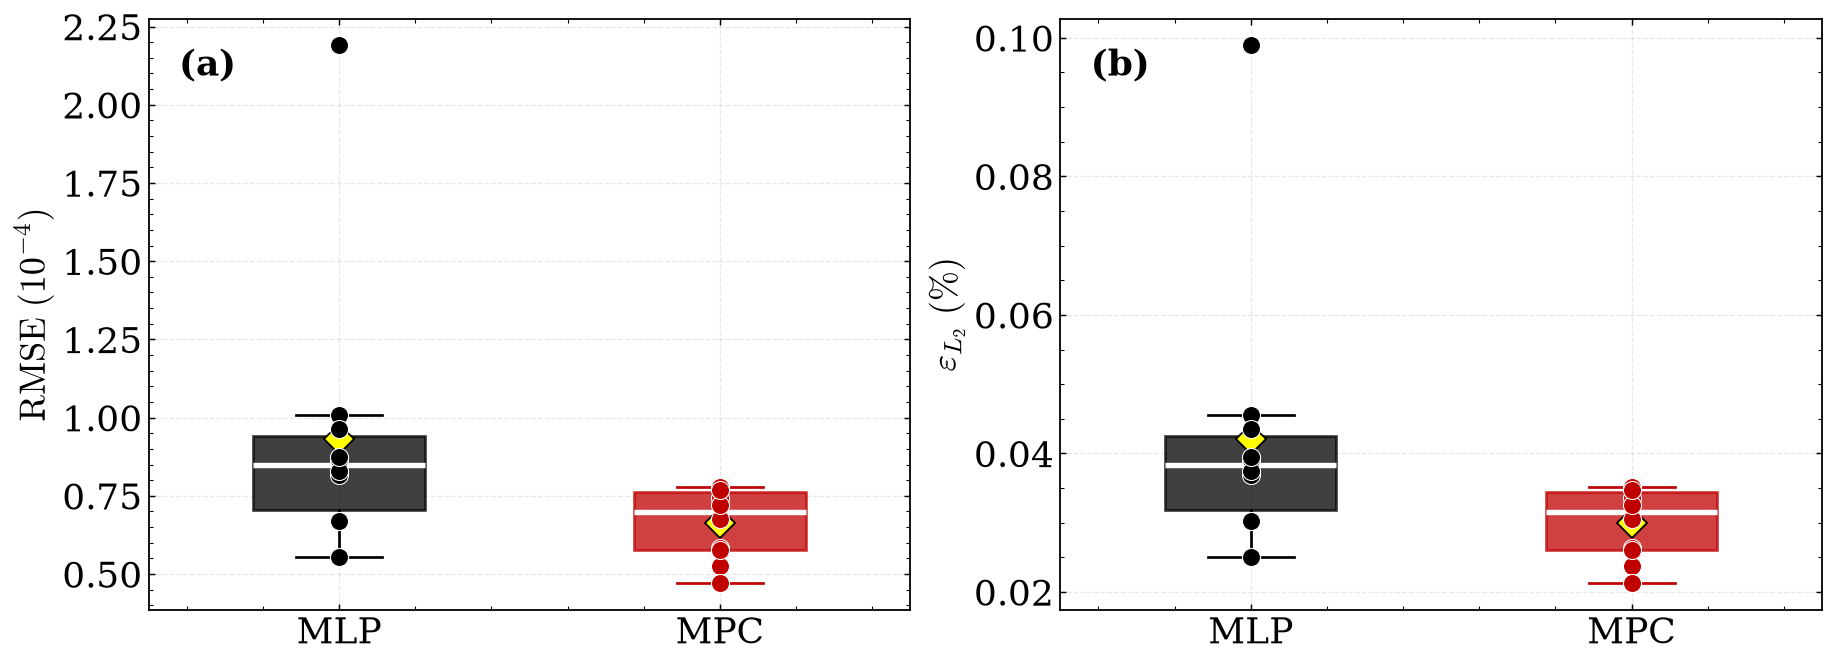

In [7]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    constrained_layout=True
)

configuracoes = [
    ("rmse", r"$\mathrm{RMSE}\;(10^{-4})$", 1e4),
    ("relative_l2", r"$\varepsilon_{L_2}\;(\%)$", 100),
]

letras = ["(a)", "(b)"]
modelos = ["MLP", "MPC"]

for ax, (coluna, ylabel, fator), letra in zip(
    axes, configuracoes, letras
):

    valores = [
        metricas.loc[
            metricas["modelo"] == modelo, coluna
        ].to_numpy() * fator
        for modelo in modelos
    ]

    bp = ax.boxplot(
        valores,
        positions=[1, 2],
        widths=0.45,
        patch_artist=True,
        showfliers=False,
        whiskerprops=dict(linewidth=1.5),
        capprops=dict(linewidth=1.5),
        showmeans=True,
        meanprops=dict(
            marker="D",
            markerfacecolor="yellow",
            markeredgecolor="black",
            markersize=12
        ),
        medianprops=dict(
            color="white",
            linewidth=3
        ),
    )

    for i, modelo in enumerate(modelos):
        cor = CORES[modelo]

        bp["boxes"][i].set(
            facecolor=cor,
            edgecolor=cor,
            alpha=0.75,
            linewidth=1.5
        )

        bp["whiskers"][2*i].set_color(cor)
        bp["whiskers"][2*i+1].set_color(cor)
        bp["caps"][2*i].set_color(cor)
        bp["caps"][2*i+1].set_color(cor)

        # Valores individuais das sementes
        ax.scatter(
            np.full(len(valores[i]), i + 1),
            valores[i],
            color=cor,
            edgecolor="white",
            linewidth=0.6,
            s=100,
            zorder=3
        )

    ax.text(
        0.04, 0.95,
        letra,
        transform=ax.transAxes,
        fontsize=20,
        fontweight="bold",
        va="top",
        ha="left"
    )

    ax.set_xticks([1, 2])
    ax.set_xticklabels(modelos, fontsize=20)
    ax.set_ylabel(ylabel, fontsize=20)

    ax.tick_params(
        axis="both",
        which="both",
        direction="in",
        top=True,
        right=True,
        labelsize=20
    )

    ax.grid(
        True,
        which="major",
        linestyle="--",
        linewidth=0.7,
        alpha=0.3
    )

    ax.set_axisbelow(True)

plt.savefig("../paper/figs/metrics_main.png", dpi=300, bbox_inches="tight")
plt.show()

(a) MLP | Best  | seed=1958 | val_mse=2.003e-09
(b) MPC | Best  | seed=1925 | val_mse=1.670e-09
(c) MLP | Worst | seed=1962 | val_mse=4.419e-08
(d) MPC | Worst | seed=2025 | val_mse=7.316e-09
(a) MLP Best: RMSE = 5.549706e-05
(b) MPC Best: RMSE = 5.241993e-05
(c) MLP Worst: RMSE = 2.189662e-04
(d) MPC Worst: RMSE = 7.687842e-05


/tmp/ipykernel_226116/690588472.py:231: UserWarning: Log scale: values of z <= 0 have been masked
  ax.contourf(
/tmp/ipykernel_226116/690588472.py:231: UserWarning: Log scale: values of z <= 0 have been masked
  ax.contourf(
/tmp/ipykernel_226116/690588472.py:231: UserWarning: Log scale: values of z <= 0 have been masked
  ax.contourf(
/tmp/ipykernel_226116/690588472.py:231: UserWarning: Log scale: values of z <= 0 have been masked
  ax.contourf(


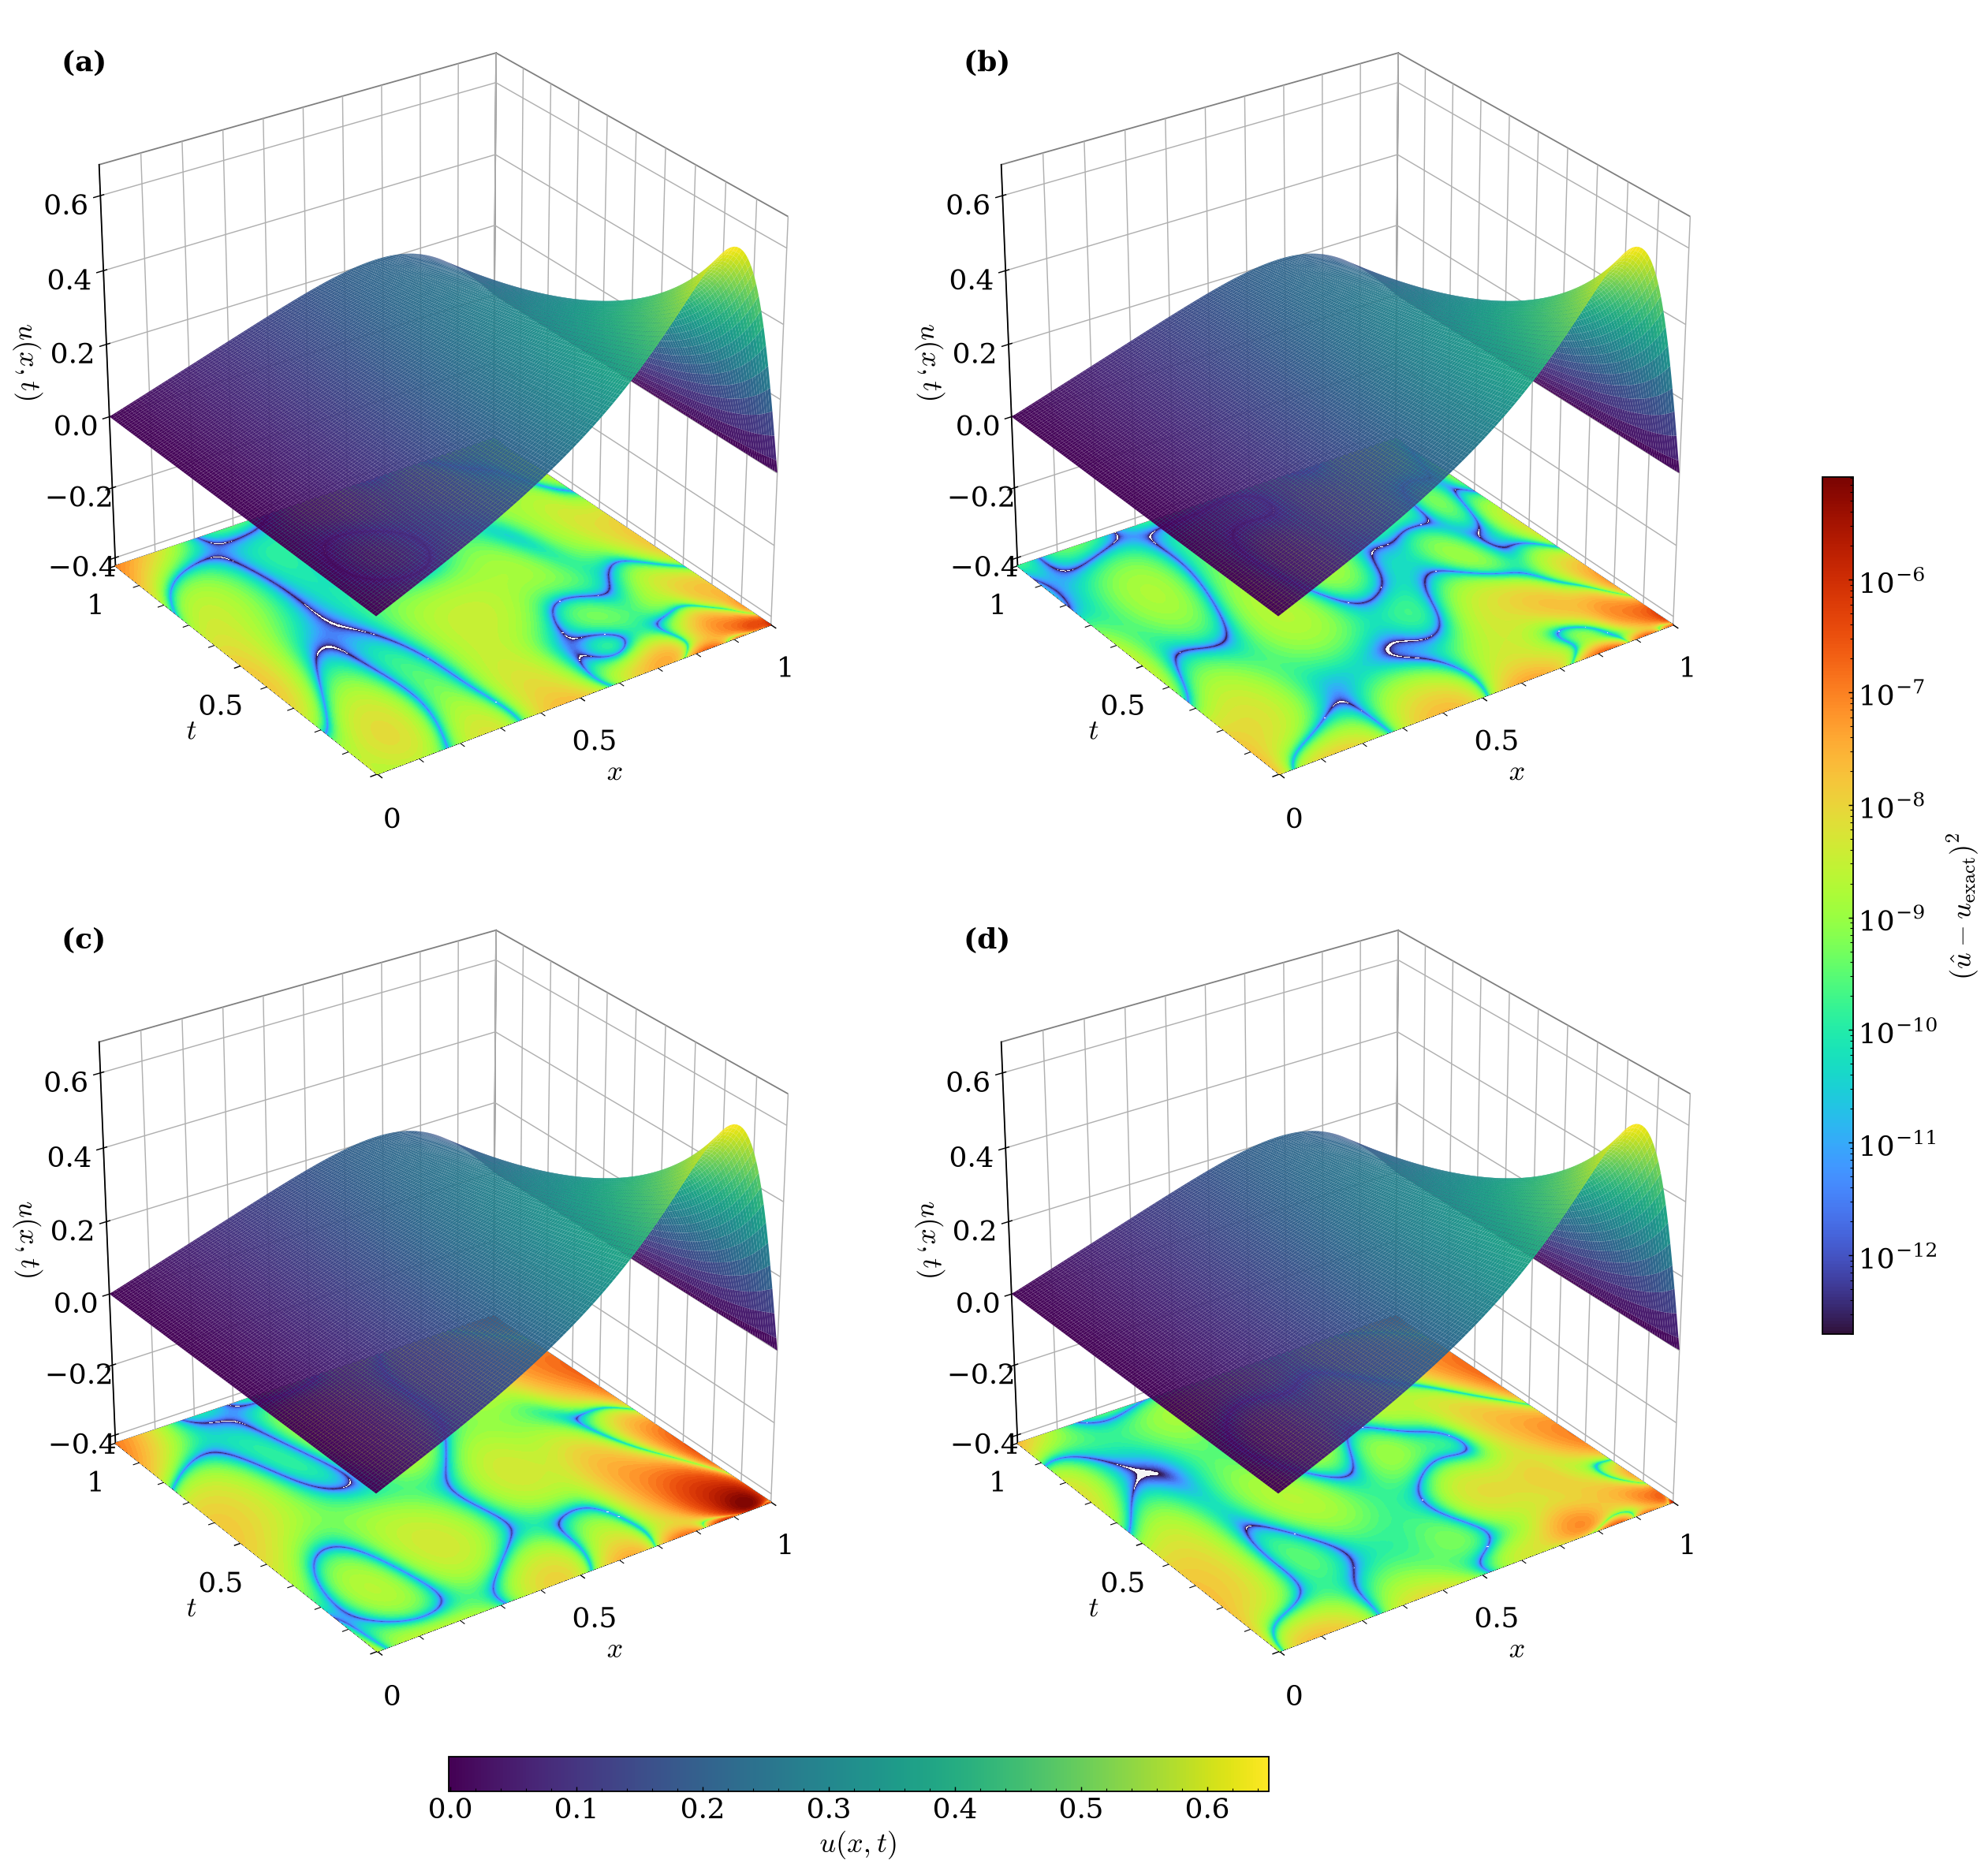

In [22]:
from pathlib import Path
from copy import deepcopy

import numpy as np
import torch
import matplotlib.pyplot as plt

from matplotlib import colors, ticker
from matplotlib.cm import ScalarMappable

# ==================================================
# 1. Selecionar melhores e piores sementes
# ==================================================

melhor_mlp = metricas_mlp.loc[
    metricas_mlp["best_val_mse"].idxmin()
]

pior_mlp = metricas_mlp.loc[
    metricas_mlp["best_val_mse"].idxmax()
]

melhor_mpc = metricas_mpc.loc[
    metricas_mpc["best_val_mse"].idxmin()
]

pior_mpc = metricas_mpc.loc[
    metricas_mpc["best_val_mse"].idxmax()
]

selecoes = [
    ("MLP", "Best", melhor_mlp, "(a)"),
    ("MPC", "Best", melhor_mpc, "(b)"),
    ("MLP", "Worst", pior_mlp, "(c)"),
    ("MPC", "Worst", pior_mpc, "(d)")
]

for nome, tipo, dados, letra in selecoes:
    print(
        f"{letra} {nome:3s} | {tipo:5s} | "
        f"seed={int(dados['seed'])} | "
        f"val_mse={dados['best_val_mse']:.3e}"
    )

# ==================================================
# 2. Carregar checkpoints
# ==================================================

def carregar_modelo(modelo_base, dados):
    modelo = deepcopy(modelo_base).cpu()

    checkpoint = (
        Path(dados["arquivo"]).parent / "best.pt"
    )

    modelo.load_state_dict(
        torch.load(
            checkpoint,
            map_location="cpu",
            weights_only=True
        )
    )

    modelo.eval()
    return modelo


modelos = {
    ("MLP", "Best"): carregar_modelo(modelo_mlp, melhor_mlp),
    ("MPC", "Best"): carregar_modelo(modelo_mpc, melhor_mpc),
    ("MLP", "Worst"): carregar_modelo(modelo_mlp, pior_mlp),
    ("MPC", "Worst"): carregar_modelo(modelo_mpc, pior_mpc),
}

# ==================================================
# 3. Grade de teste: 250 x 250
# ==================================================

n_grid = 250

x = np.linspace(0, 1, n_grid)
t = np.linspace(0, 1, n_grid)

X, T = np.meshgrid(x, t)

coords = torch.tensor(
    np.column_stack([X.ravel(), T.ravel()]),
    dtype=torch.float32
)

# ==================================================
# 4. Solução analítica e inferências
# ==================================================

@torch.no_grad()
def inferir(modelo, coords, batch_size=2048):
    return np.concatenate([
        modelo(chunk).detach().cpu().numpy().ravel()
        for chunk in coords.split(batch_size)
    ])


U_exata = (
    exact(coords)
    .detach()
    .cpu()
    .numpy()
    .reshape(X.shape)
)

resultados = {}

for nome, tipo, dados, letra in selecoes:

    U = inferir(
        modelos[(nome, tipo)],
        coords
    ).reshape(X.shape)

    E = (U - U_exata)**2

    resultados[(nome, tipo)] = {
        "U": U,
        "E": E,
        "rmse": np.sqrt(E.mean())
    }

    print(
        f"{letra} {nome} {tipo}: "
        f"RMSE = {np.sqrt(E.mean()):.6e}"
    )

# ==================================================
# 5. Escalas compartilhadas
# ==================================================

todas_solucoes = [
    U_exata,
    *[r["U"] for r in resultados.values()]
]

u_min = min(U.min() for U in todas_solucoes)
u_max = max(U.max() for U in todas_solucoes)

norm_u = colors.Normalize(
    vmin=u_min,
    vmax=u_max
)

todos_erros = np.concatenate([
    r["E"].ravel()
    for r in resultados.values()
])

erros_positivos = todos_erros[todos_erros > 0]

vmin_e = np.percentile(erros_positivos, 1)
vmax_e = erros_positivos.max()

norm_e = colors.LogNorm(
    vmin=vmin_e,
    vmax=vmax_e
)

# Paleta com maior contraste
cmap_e = plt.get_cmap("turbo").copy()
cmap_e.set_under("#f5f5f5")

# ==================================================
# 6. Maior distância entre superfície e projeção
# ==================================================

amplitude = u_max - u_min

z_floor = u_min - 0.65 * amplitude
z_top = u_max + 0.05 * amplitude

# ==================================================
# 7. Figura 2 x 2 — layout com mais espaçamento
# ==================================================

fig = plt.figure(
    figsize=(20, 19),
    constrained_layout=False
)

fig.subplots_adjust(
    left=0.04,
    right=0.88,
    bottom=0.10,
    top=0.96,
    wspace=0.1,
    hspace=0.1
)

for i, (nome, tipo, dados, letra) in enumerate(selecoes):

    ax = fig.add_subplot(
        2, 2, i + 1,
        projection="3d"
    )

    U = resultados[(nome, tipo)]["U"]
    E = resultados[(nome, tipo)]["E"]

    # ----------------------------------------------
    # Superfície da inferência
    # ----------------------------------------------

    ax.plot_surface(
        X, T, U,
        cmap="viridis",
        norm=norm_u,
        rstride=2,
        cstride=2,
        linewidth=0,
        antialiased=True,
        alpha=1.0
    )

    # ----------------------------------------------
    # Projeção 2D do erro quadrático
    # ----------------------------------------------

    levels = np.geomspace(
        vmin_e,
        vmax_e,
        60
    )

    ax.contourf(
        X, T, E,
        zdir="z",
        offset=z_floor,
        levels=levels,
        cmap=cmap_e,
        norm=norm_e,
        extend="min",
        alpha=1.0
    )

    # ----------------------------------------------
    # Letra do painel
    # ----------------------------------------------

    ax.text2D(
        0.04, 0.95,
        letra,
        transform=ax.transAxes,
        fontsize=20,
        fontweight="bold",
        va="top",
        ha="left"
    )

    # ----------------------------------------------
    # Eixos
    # ----------------------------------------------

    ax.set_xlabel(
        r"$x$",
        fontsize=20,
        labelpad=15
    )

    ax.set_ylabel(
        r"$t$",
        fontsize=20,
        labelpad=15
    )

    ax.set_zlabel(
        r"$u(x,t)$",
        fontsize=20,
        labelpad=15
    )

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_zlim(z_floor, z_top)

    ax.set_xticks([0, 0.5, 1])
    ax.set_yticks([0, 0.5, 1])

    ax.set_xticklabels(["0", "0.5", "1"])
    ax.set_yticklabels(["", "0.5", "1"])

    ax.tick_params(
        axis="both",
        which="major",
        labelsize=20,
        pad=7
    )

    ax.view_init(
        elev=28,
        azim=-125
    )

    ax.set_box_aspect((1, 1, 0.95))

    # Painéis transparentes
    for axis in [ax.xaxis, ax.yaxis, ax.zaxis]:
        axis.pane.fill = False
        axis.pane.set_edgecolor("black")

    # Grid ativado
    ax.grid(True)

# ==================================================
# 8. Barras de cores compartilhadas
# ==================================================

sm_u = ScalarMappable(
    norm=norm_u,
    cmap="viridis"
)
sm_u.set_array([])

sm_e = ScalarMappable(
    norm=norm_e,
    cmap=cmap_e
)
sm_e.set_array([])

# ----------------------------------------------
# Solução — barra horizontal
# ----------------------------------------------

cax_u = fig.add_axes([
    0.25, 0.045, 0.40, 0.018
])

cbar_u = fig.colorbar(
    sm_u,
    cax=cax_u,
    orientation="horizontal"
)

cbar_u.set_label(
    r"$u(x,t)$",
    fontsize=20
)

cbar_u.ax.tick_params(
    labelsize=20
)

# ----------------------------------------------
# Erro quadrático — barra vertical
# ----------------------------------------------

cax_e = fig.add_axes([
    0.92, 0.28, 0.015, 0.44
])

cbar_e = fig.colorbar(
    sm_e,
    cax=cax_e,
    orientation="vertical"
)

cbar_e.set_label(
    r"$(\hat{u}-u_{\mathrm{exact}})^2$",
    fontsize=20
)

cbar_e.formatter = ticker.LogFormatterMathtext()
cbar_e.update_ticks()

cbar_e.ax.tick_params(
    labelsize=20
)

plt.savefig("../paper/figs/solutions_main.png", dpi=300, bbox_inches="tight")

plt.show()

In [8]:
from pathlib import Path
import json
import pandas as pd

# Caminho dos experimentos
BASE = Path("/home/camaral/inct_cq_hybrid_nn/runs/pinn")
PASTA_WIDTH = BASE / "mlp_width_2708"

# Parâmetros das MLPs: 2 entradas, 4 camadas ocultas, 1 saída
PARAMETROS_WIDTH = {
    249: 8,
    881: 16,
    3297: 32,
    12737: 64,
    50049: 128,
}

# Carregar resultados
registros = []

for arquivo in sorted(PASTA_WIDTH.rglob("metrics.json")):
    with open(arquivo) as f:
        m = json.load(f)

    m["seed"] = int(arquivo.parent.name.split("_")[-1])
    m["width"] = PARAMETROS_WIDTH[int(m["parameters"])]

    registros.append(m)

df_width = pd.DataFrame(registros)

# Agrupar por largura
tabela_width = (
    df_width.groupby("width", as_index=False)
    .agg(
        sementes=("seed", "nunique"),
        parametros=("parameters", "first"),
        val_mse_media=("best_val_mse", "mean"),
        val_mse_std=("best_val_mse", "std"),
        rmse_medio=("rmse", "mean"),
        rmse_std=("rmse", "std"),
        mae_medio=("mae", "mean"),
        l2_relativo_medio=("relative_l2", "mean"),
    )
    .sort_values("rmse_medio")
    .reset_index(drop=True)
)

print("Ranking das MLPs clássicas — 4 camadas ocultas")

display(
    tabela_width.style.format({
        "parametros": "{:,.0f}",
        "val_mse_media": "{:.3e}",
        "val_mse_std": "{:.3e}",
        "rmse_medio": "{:.3e}",
        "rmse_std": "{:.3e}",
        "mae_medio": "{:.3e}",
        "l2_relativo_medio": "{:.3e}",
    })
)

Ranking das MLPs clássicas — 4 camadas ocultas


,width,sementes,parametros,val_mse_media,val_mse_std,rmse_medio,rmse_std,mae_medio,l2_relativo_medio
0,128,10,"50,049",3.209e-09,3.385e-09,5.741e-05,2.502e-05,2.763e-05,2.593e-04
1,64,10,"12,737",4.298e-09,5.383e-09,6.403e-05,3.080e-05,3.244e-05,2.892e-04
2,32,10,"3,297",9.383e-09,1.240e-08,9.326e-05,4.683e-05,5.310e-05,4.213e-04
3,16,10,881,3.532e-08,2.030e-08,1.863e-04,5.512e-05,1.053e-04,8.416e-04
4,8,10,249,9.946e-08,3.848e-08,3.267e-04,7.209e-05,2.110e-04,1.476e-03


In [21]:
registros = []

for nome, tipo, dados, letra in selecoes:

    rmse_salvo = dados["rmse"]
    rmse_calculado = resultados[(nome, tipo)]["rmse"]

    registros.append({
        "Modelo": nome,
        "Seleção": tipo,
        "Seed": int(dados["seed"]),
        "RMSE salvo": rmse_salvo,
        "RMSE recalculado": rmse_calculado,
        "Diferença relativa (%)": (
            100 * abs(rmse_calculado - rmse_salvo) / rmse_salvo
        )
    })

df_verificacao = pd.DataFrame(registros)

display(
    df_verificacao.style.format({
        "RMSE salvo": "{:.8e}",
        "RMSE recalculado": "{:.8e}",
        "Diferença relativa (%)": "{:.4f}"
    })
)

,Modelo,Seleção,Seed,RMSE salvo,RMSE recalculado,Diferença relativa (%)
0,MLP,Best,1958,5.54970720e-05,5.54970611e-05,0.0000
1,MPC,Best,1925,5.24200041e-05,5.24199349e-05,0.0001
2,MLP,Worst,1962,2.18966292e-04,2.18966248e-04,0.0000
3,MPC,Worst,2025,7.68784885e-05,7.68784230e-05,0.0001


# MPC variation

RMSE médio MLP: 9.326027e-05
Sementes MLP: 10


,qubits,layers,rmse_mean,rmse_std,sementes
0,3,1,0.000095,0.000027,10
1,3,3,0.000094,0.000018,10
2,3,5,0.000079,0.000019,10
3,5,1,0.000087,0.000024,10
4,5,3,0.000066,0.000011,10
5,5,5,0.000063,0.000016,10
6,7,1,0.000071,0.000015,10
7,7,3,0.000066,0.000012,10
8,7,5,0.000060,0.000012,10


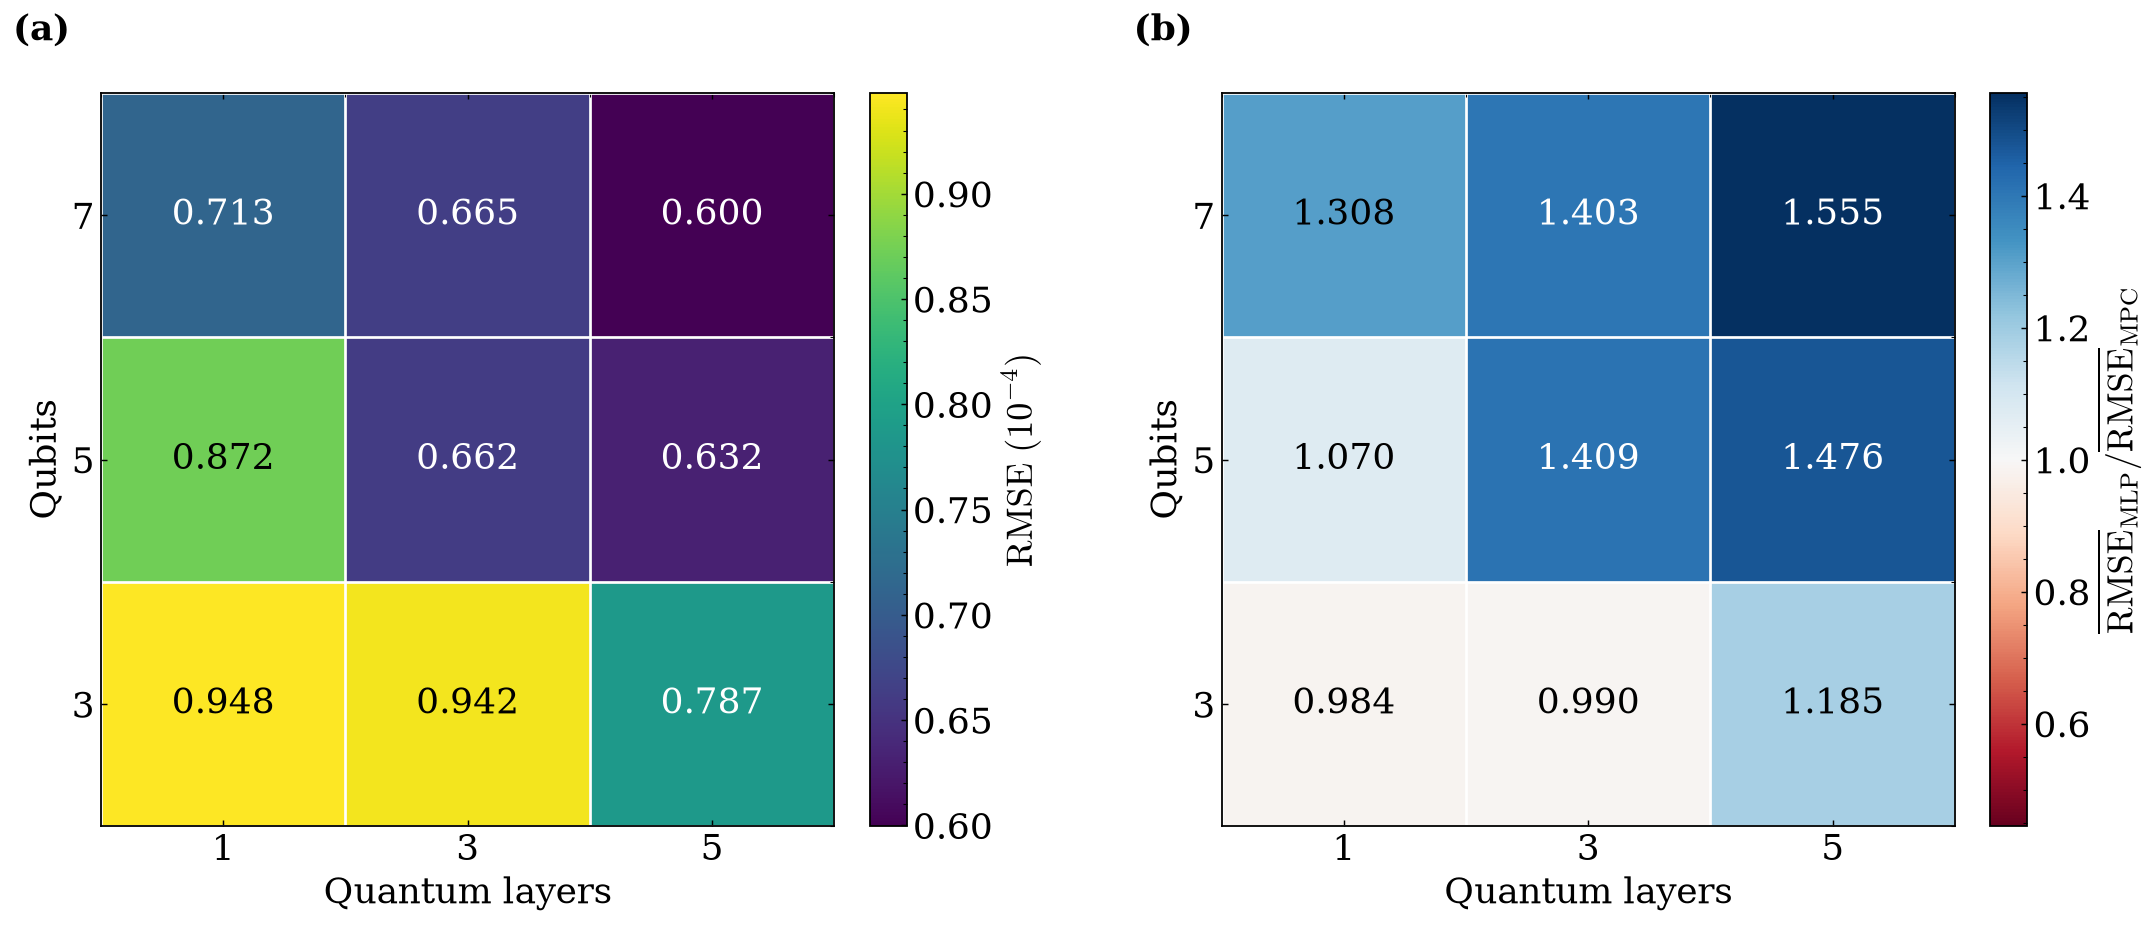

In [25]:
from pathlib import Path
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colors

# ==================================================
# 1. Caminhos e configurações
# ==================================================

BASE = Path("/home/camaral/inct_cq_hybrid_nn/runs/pinn")

PASTA_MLP = BASE / "mlp_depth_2706/results/burgers/pinn_mlp_depth_4"
PASTA_MPC = BASE / "mpc_serial"

qubits = [3, 5, 7]
layers = [1, 3, 5]

# ==================================================
# 2. Carregar resultados da MLP
# ==================================================

registros_mlp = []

for arquivo in sorted(PASTA_MLP.glob("seed_*/metrics.json")):

    with open(arquivo) as f:
        m = json.load(f)

    registros_mlp.append({
        "seed": int(arquivo.parent.name.split("_")[-1]),
        "rmse": m["rmse"]
    })

df_mlp = pd.DataFrame(registros_mlp)

rmse_mlp = df_mlp["rmse"].mean()

# ==================================================
# 3. Carregar resultados do MPC
# ==================================================

registros_mpc = []

arquivos = sorted(
    PASTA_MPC.glob(
        "0*_*/q*_l*_z_polynomial/seed_*/metrics.json"
    )
)

for arquivo in arquivos:

    configuracao = arquivo.parent.parent.name
    seed = int(arquivo.parent.name.split("_")[-1])

    n_qubits, n_layers = map(
        int,
        re.search(r"q(\d+)_l(\d+)", configuracao).groups()
    )

    with open(arquivo) as f:
        m = json.load(f)

    registros_mpc.append({
        "qubits": n_qubits,
        "layers": n_layers,
        "seed": seed,
        "rmse": m["rmse"]
    })

df_mpc = pd.DataFrame(registros_mpc)

# Remover configurações repetidas entre etapas
df_mpc = df_mpc.drop_duplicates(
    subset=["qubits", "layers", "seed"]
)

df_mpc = df_mpc[
    df_mpc["qubits"].isin(qubits)
    & df_mpc["layers"].isin(layers)
].copy()

# ==================================================
# 4. Média do RMSE por configuração
# ==================================================

resumo_mpc = (
    df_mpc.groupby(["qubits", "layers"])
    .agg(
        rmse_mean=("rmse", "mean"),
        rmse_std=("rmse", "std"),
        sementes=("seed", "nunique")
    )
    .reset_index()
)

print(f"RMSE médio MLP: {rmse_mlp:.6e}")
print(f"Sementes MLP: {df_mlp['seed'].nunique()}")

display(resumo_mpc)

# ==================================================
# 5. Matrizes dos heatmaps
# ==================================================

mat_rmse = (
    resumo_mpc.pivot(
        index="qubits",
        columns="layers",
        values="rmse_mean"
    )
    .reindex(index=qubits, columns=layers)
    .to_numpy()
)

# RMSE em unidades de 10^-4
mat_rmse_plot = mat_rmse * 1e4

# Razão: RMSE MLP / RMSE MPC
mat_razao = rmse_mlp / mat_rmse

# ==================================================
# 6. Estilo Mathematica
# ==================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 20,
    "mathtext.fontset": "cm",
    "axes.linewidth": 1.0,
    "axes.edgecolor": "black",
    "axes.spines.top": True,
    "axes.spines.right": True,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "figure.dpi": 130,
    "savefig.dpi": 300
})

# ==================================================
# 7. Escalas de cores
# ==================================================

# RMSE: valores menores são melhores
norm_rmse = colors.Normalize(
    vmin=np.nanmin(mat_rmse_plot),
    vmax=np.nanmax(mat_rmse_plot)
)

# Razão: 1 = desempenho equivalente
limite = max(
    abs(np.nanmin(mat_razao) - 1),
    abs(np.nanmax(mat_razao) - 1)
)

norm_razao = colors.TwoSlopeNorm(
    vmin=1 - limite,
    vcenter=1,
    vmax=1 + limite
)

# ==================================================
# 8. Figura
# ==================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 7),
    constrained_layout=True
)

configuracoes = [
    (
        mat_rmse_plot,
        "viridis",
        norm_rmse,
        r"$\mathrm{RMSE}\;(10^{-4})$",
        "(a)"
    ),
    (
        mat_razao,
        "RdBu",
        norm_razao,
        r"$\overline{\mathrm{RMSE}}_{\mathrm{MLP}}"
        r"/\overline{\mathrm{RMSE}}_{\mathrm{MPC}}$",
        "(b)"
    )
]

for ax, (matriz, cmap, norm, label, letra) in zip(
    axes, configuracoes
):

    im = ax.imshow(
        matriz,
        cmap=cmap,
        norm=norm,
        origin="lower",
        aspect="equal",
        interpolation="nearest"
    )

    # ----------------------------------------------
    # Valores numéricos nas células
    # ----------------------------------------------

    for i in range(len(qubits)):
        for j in range(len(layers)):

            valor = matriz[i, j]

            rgba = im.cmap(im.norm(valor))

            luminosidade = (
                0.2126 * rgba[0]
                + 0.7152 * rgba[1]
                + 0.0722 * rgba[2]
            )

            cor_texto = (
                "black" if luminosidade > 0.55 else "white"
            )

            ax.text(
                j, i,
                f"{valor:.3f}",
                ha="center",
                va="center",
                fontsize=20,
                color=cor_texto
            )

    # ----------------------------------------------
    # Eixos
    # ----------------------------------------------

    ax.set_xticks(range(len(layers)))
    ax.set_xticklabels(layers, fontsize=20)

    ax.set_yticks(range(len(qubits)))
    ax.set_yticklabels(qubits, fontsize=20)

    ax.set_xlabel(
        "Quantum layers",
        fontsize=20
    )

    ax.set_ylabel(
        "Qubits",
        fontsize=20
    )

    # ----------------------------------------------
    # Linhas entre as células
    # ----------------------------------------------

    ax.set_xticks(
        np.arange(-0.5, len(layers), 1),
        minor=True
    )

    ax.set_yticks(
        np.arange(-0.5, len(qubits), 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="white",
        linestyle="-",
        linewidth=1.5
    )

    ax.tick_params(
        axis="both",
        which="major",
        direction="in",
        top=True,
        right=True,
        labelsize=20
    )

    ax.tick_params(
        which="minor",
        bottom=False,
        left=False
    )

    # ----------------------------------------------
    # Identificação do painel
    # ----------------------------------------------

    ax.text(
        -0.12, 1.06,
        letra,
        transform=ax.transAxes,
        fontsize=20,
        fontweight="bold",
        va="bottom",
        ha="left"
    )

    # ----------------------------------------------
    # Barra de cores
    # ----------------------------------------------

    cbar = fig.colorbar(
        im,
        ax=ax,
        fraction=0.046,
        pad=0.04
    )

    cbar.set_label(
        label,
        fontsize=20
    )

    cbar.ax.tick_params(
        labelsize=20
    )


plt.savefig("../paper/figs/rmse_heatmap_quantum.png", dpi=300, bbox_inches="tight")
plt.show()

,sementes,rmse_mean,rmse_median,rmse_std
observavel,,,,
Z,10,6.618231e-05,6.989094e-05,1.141433e-05
ZZ,10,5.714378e-05,5.350407e-05,1.298647e-05
XX,10,4.387674e-05,3.148046e-05,2.093579e-05
YY,10,5.293720e-05,5.235470e-05,1.265482e-05
Mixed,10,5.170145e-05,5.174772e-05,1.171310e-05


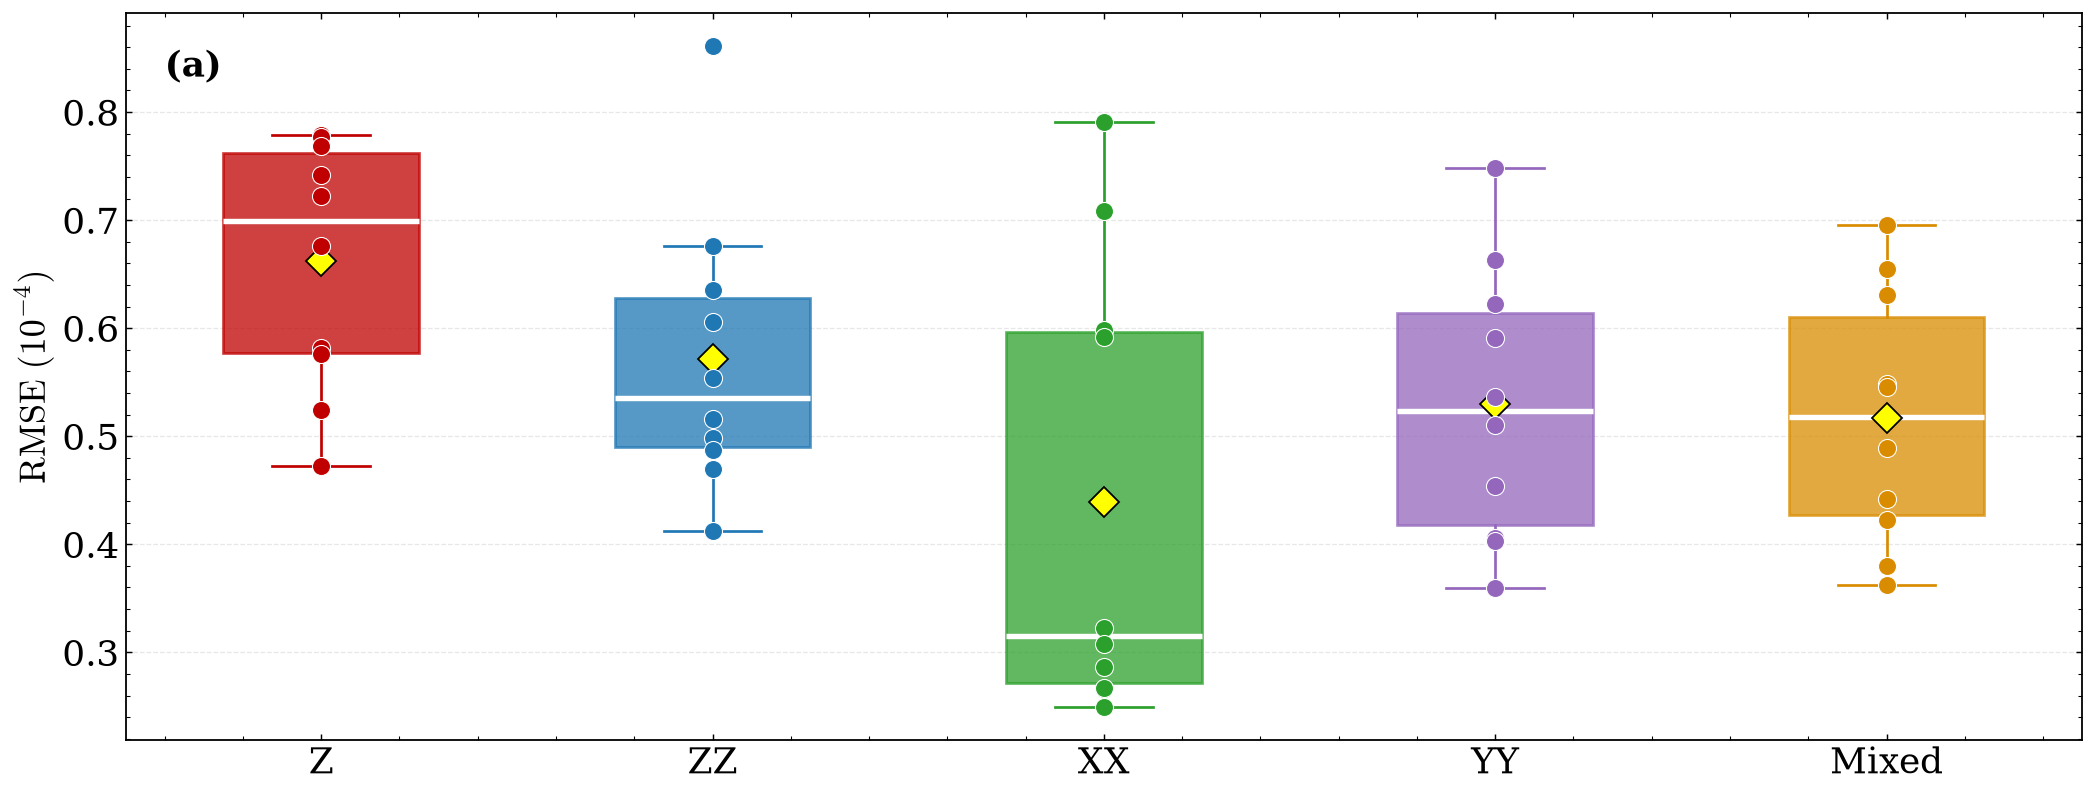

In [29]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==================================================
# 1. Caminhos e configurações
# ==================================================

PASTA_MPC = BASE / "mpc_serial"

observaveis = ["z", "zz", "xx", "yy", "mixed"]

cores_obs = {
    "MLP": "#000000",
    "Z": "#C00000",
    "ZZ": "#1F77B4",
    "XX": "#2CA02C",
    "YY": "#9467BD",
    "Mixed": "#D98C00"
}

# ==================================================
# 2. Carregar métricas dos observáveis
# ==================================================

registros = []

for obs in observaveis:

    arquivos = sorted(
        PASTA_MPC.glob(
            f"0*_*/q5_l3_{obs}_polynomial/seed_*/metrics.json"
        )
    )

    for arquivo in arquivos:

        with open(arquivo) as f:
            m = json.load(f)

        registros.append({
            "observavel": obs.upper() if obs != "mixed" else "Mixed",
            "seed": int(arquivo.parent.name.split("_")[-1]),
            "rmse": m["rmse"],
            "relative_l2": m["relative_l2"]
        })

df_obs = pd.DataFrame(registros)

# Remover execuções repetidas entre etapas
df_obs = df_obs.drop_duplicates(
    subset=["observavel", "seed"]
)

# ==================================================
# 3. Adicionar MLP como referência
# ==================================================

df_mlp_obs = metricas_mlp[
    ["seed", "rmse", "relative_l2"]
].copy()

df_mlp_obs["observavel"] = "MLP"

df_plot = pd.concat(
    [df_mlp_obs, df_obs],
    ignore_index=True
)

ordem = ["Z", "ZZ", "XX", "YY", "Mixed"]

# ==================================================
# 4. Resumo estatístico
# ==================================================

resumo_obs = (
    df_plot.groupby("observavel")
    .agg(
        sementes=("seed", "nunique"),
        rmse_mean=("rmse", "mean"),
        rmse_median=("rmse", "median"),
        rmse_std=("rmse", "std")
    )
    .reindex(ordem)
)

display(
    resumo_obs.style.format({
        "rmse_mean": "{:.6e}",
        "rmse_median": "{:.6e}",
        "rmse_std": "{:.6e}"
    })
)

# ==================================================
# 5. Boxplot
# ==================================================

fig, ax = plt.subplots(
    figsize=(16, 6),
    constrained_layout=True
)

valores = [
    df_plot.loc[
        df_plot["observavel"] == obs,
        "rmse"
    ].to_numpy() * 1e4
    for obs in ordem
]

bp = ax.boxplot(
    valores,
    positions=np.arange(1, len(ordem) + 1),
    widths=0.5,
    patch_artist=True,
    showfliers=False,
    showmeans=True,
    meanprops=dict(
        marker="D",
        markerfacecolor="yellow",
        markeredgecolor="black",
        markersize=12
    ),
    medianprops=dict(
        color="white",
        linewidth=3
    ),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5)
)

for i, obs in enumerate(ordem):

    cor = cores_obs[obs]

    bp["boxes"][i].set(
        facecolor=cor,
        edgecolor=cor,
        alpha=0.75,
        linewidth=1.5
    )

    for elemento in [
        bp["whiskers"][2*i],
        bp["whiskers"][2*i+1],
        bp["caps"][2*i],
        bp["caps"][2*i+1]
    ]:
        elemento.set_color(cor)

    # Sementes individuais
    ax.scatter(
        np.full(len(valores[i]), i + 1),
        valores[i],
        color=cor,
        edgecolor="white",
        linewidth=0.6,
        s=100,
        zorder=3
    )

# ==================================================
# 6. Formatação Mathematica
# ==================================================

ax.set_xticks(np.arange(1, len(ordem) + 1))
ax.set_xticklabels(ordem, fontsize=20)

ax.set_ylabel(
    r"$\mathrm{RMSE}\;(10^{-4})$",
    fontsize=20
)

ax.tick_params(
    axis="both",
    which="both",
    direction="in",
    top=True,
    right=True,
    labelsize=20
)

ax.grid(
    True,
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.3
)

ax.set_axisbelow(True)

ax.text(
    0.02, 0.95,
    "(a)",
    transform=ax.transAxes,
    fontsize=20,
    fontweight="bold",
    va="top",
    ha="left"
)

plt.savefig("../paper/figs/observables_quantum.png", dpi=300, bbox_inches="tight")
plt.show()

,sementes,rmse_mean,rmse_median,rmse_std
acoplamento,,,,
MLP,10,9.326027e-05,8.476886e-05,4.682885e-05
Polynomial,10,5.170145e-05,5.174772e-05,1.171310e-05
Product,10,4.800780e-05,4.925946e-05,1.862445e-05


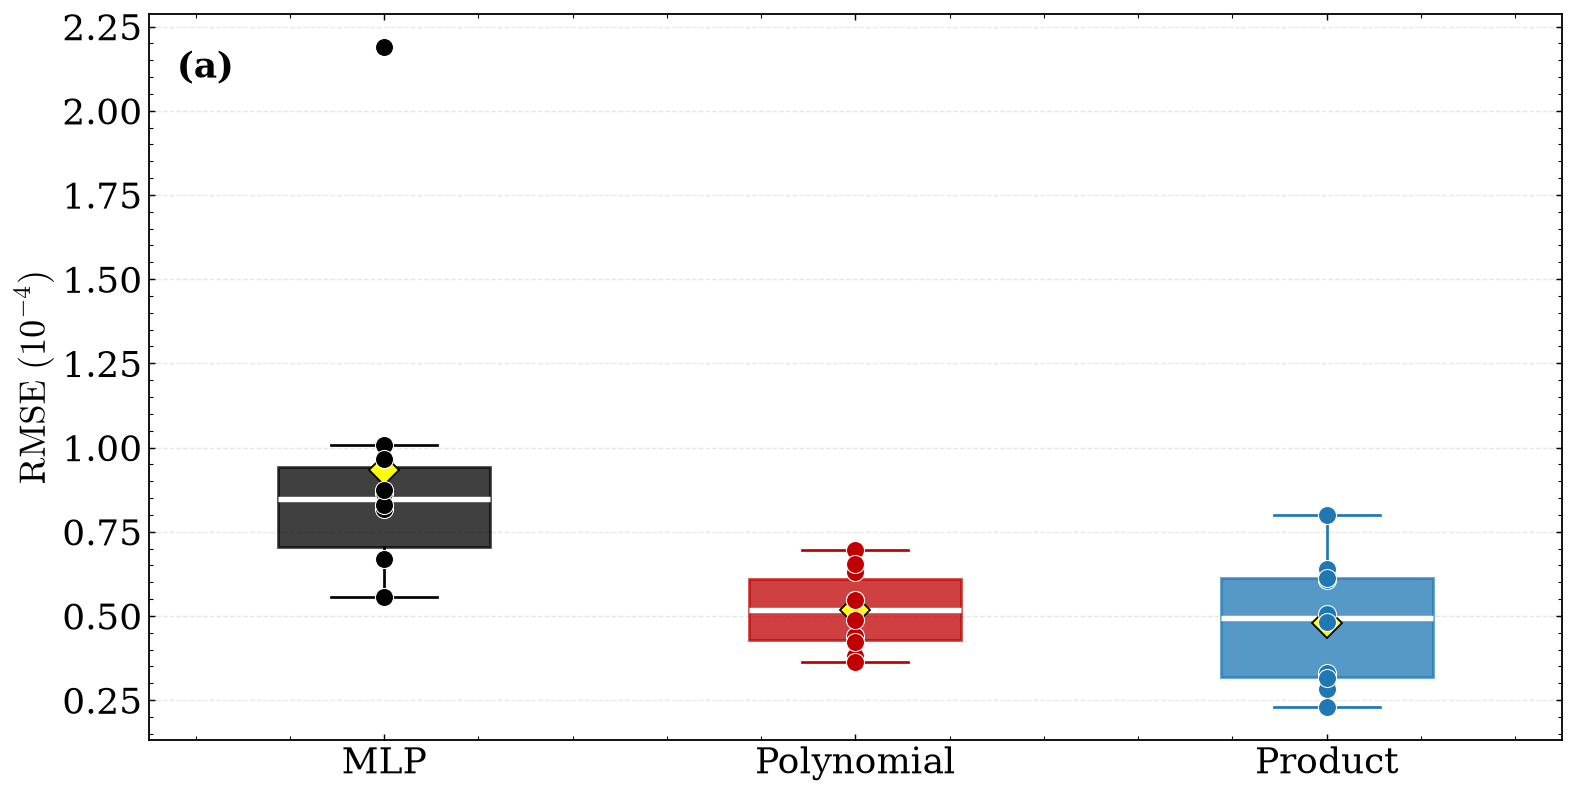

In [27]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==================================================
# 1. Caminhos e configurações
# ==================================================

PASTA_MPC = BASE / "mpc_serial"

acoplamentos = ["polynomial", "product"]

cores = {
    "MLP": "#000000",
    "Polynomial": "#C00000",
    "Product": "#1F77B4"
}

# ==================================================
# 2. Carregar métricas dos acoplamentos
# ==================================================

registros = []

for acoplamento in acoplamentos:

    arquivos = sorted(
        PASTA_MPC.glob(
            f"0*_*/q5_l3_mixed_{acoplamento}/seed_*/metrics.json"
        )
    )

    for arquivo in arquivos:

        with open(arquivo) as f:
            m = json.load(f)

        registros.append({
            "acoplamento": acoplamento.capitalize(),
            "seed": int(arquivo.parent.name.split("_")[-1]),
            "rmse": m["rmse"],
            "relative_l2": m["relative_l2"]
        })

df_acoplamentos = pd.DataFrame(registros)

# Remover execuções repetidas entre etapas
df_acoplamentos = df_acoplamentos.drop_duplicates(
    subset=["acoplamento", "seed"]
)

# ==================================================
# 3. Adicionar MLP como referência
# ==================================================

df_mlp_acoplamentos = metricas_mlp[
    ["seed", "rmse", "relative_l2"]
].copy()

df_mlp_acoplamentos["acoplamento"] = "MLP"

df_plot_acoplamentos = pd.concat(
    [df_mlp_acoplamentos, df_acoplamentos],
    ignore_index=True
)

ordem = ["MLP", "Polynomial", "Product"]

# ==================================================
# 4. Resumo estatístico
# ==================================================

resumo_acoplamentos = (
    df_plot_acoplamentos.groupby("acoplamento")
    .agg(
        sementes=("seed", "nunique"),
        rmse_mean=("rmse", "mean"),
        rmse_median=("rmse", "median"),
        rmse_std=("rmse", "std")
    )
    .reindex(ordem)
)

display(
    resumo_acoplamentos.style.format({
        "rmse_mean": "{:.6e}",
        "rmse_median": "{:.6e}",
        "rmse_std": "{:.6e}"
    })
)

# ==================================================
# 5. Boxplot
# ==================================================

fig, ax = plt.subplots(
    figsize=(12, 6),
    constrained_layout=True
)

valores = [
    df_plot_acoplamentos.loc[
        df_plot_acoplamentos["acoplamento"] == nome,
        "rmse"
    ].to_numpy() * 1e4
    for nome in ordem
]

bp = ax.boxplot(
    valores,
    positions=np.arange(1, len(ordem) + 1),
    widths=0.45,
    patch_artist=True,
    showfliers=False,
    showmeans=True,
    meanprops=dict(
        marker="D",
        markerfacecolor="yellow",
        markeredgecolor="black",
        markersize=12
    ),
    medianprops=dict(
        color="white",
        linewidth=3
    ),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5)
)

for i, nome in enumerate(ordem):

    cor = cores[nome]

    bp["boxes"][i].set(
        facecolor=cor,
        edgecolor=cor,
        alpha=0.75,
        linewidth=1.5
    )

    for elemento in [
        bp["whiskers"][2*i],
        bp["whiskers"][2*i+1],
        bp["caps"][2*i],
        bp["caps"][2*i+1]
    ]:
        elemento.set_color(cor)

    # Valores individuais das sementes
    ax.scatter(
        np.full(len(valores[i]), i + 1),
        valores[i],
        color=cor,
        edgecolor="white",
        linewidth=0.6,
        s=100,
        zorder=3
    )

# ==================================================
# 6. Formatação Mathematica
# ==================================================

ax.set_xticks(np.arange(1, len(ordem) + 1))
ax.set_xticklabels(ordem, fontsize=20)

ax.set_ylabel(
    r"$\mathrm{RMSE}\;(10^{-4})$",
    fontsize=20
)

ax.tick_params(
    axis="both",
    which="both",
    direction="in",
    top=True,
    right=True,
    labelsize=20
)

ax.grid(
    True,
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.3
)

ax.set_axisbelow(True)

ax.text(
    0.02, 0.95,
    "(a)",
    transform=ax.transAxes,
    fontsize=20,
    fontweight="bold",
    va="top",
    ha="left"
)

plt.show()

,observavel,versao,sementes,rmse_mean,rmse_median,rmse_std,parametros
0,Mixed,Antiga,10,4.768606e-04,3.185048e-04,3.092380e-04,2403
1,Mixed,Recente,10,5.170145e-05,5.174772e-05,1.171310e-05,3459
2,XX,Antiga,10,4.541764e-04,3.306691e-04,3.678127e-04,2403
3,XX,Recente,10,4.387674e-05,3.148046e-05,2.093579e-05,3459
4,YY,Antiga,10,4.153742e-04,3.754239e-04,2.703048e-04,2403
5,YY,Recente,10,5.293720e-05,5.235470e-05,1.265482e-05,3459
6,Z,Antiga,10,5.105090e-04,4.455076e-04,2.495308e-04,2403
7,Z,Recente,10,6.618231e-05,6.989094e-05,1.141433e-05,3459
8,ZZ,Antiga,10,4.812176e-04,3.816082e-04,2.615340e-04,2403
9,ZZ,Recente,10,5.714378e-05,5.350407e-05,1.298647e-05,3459


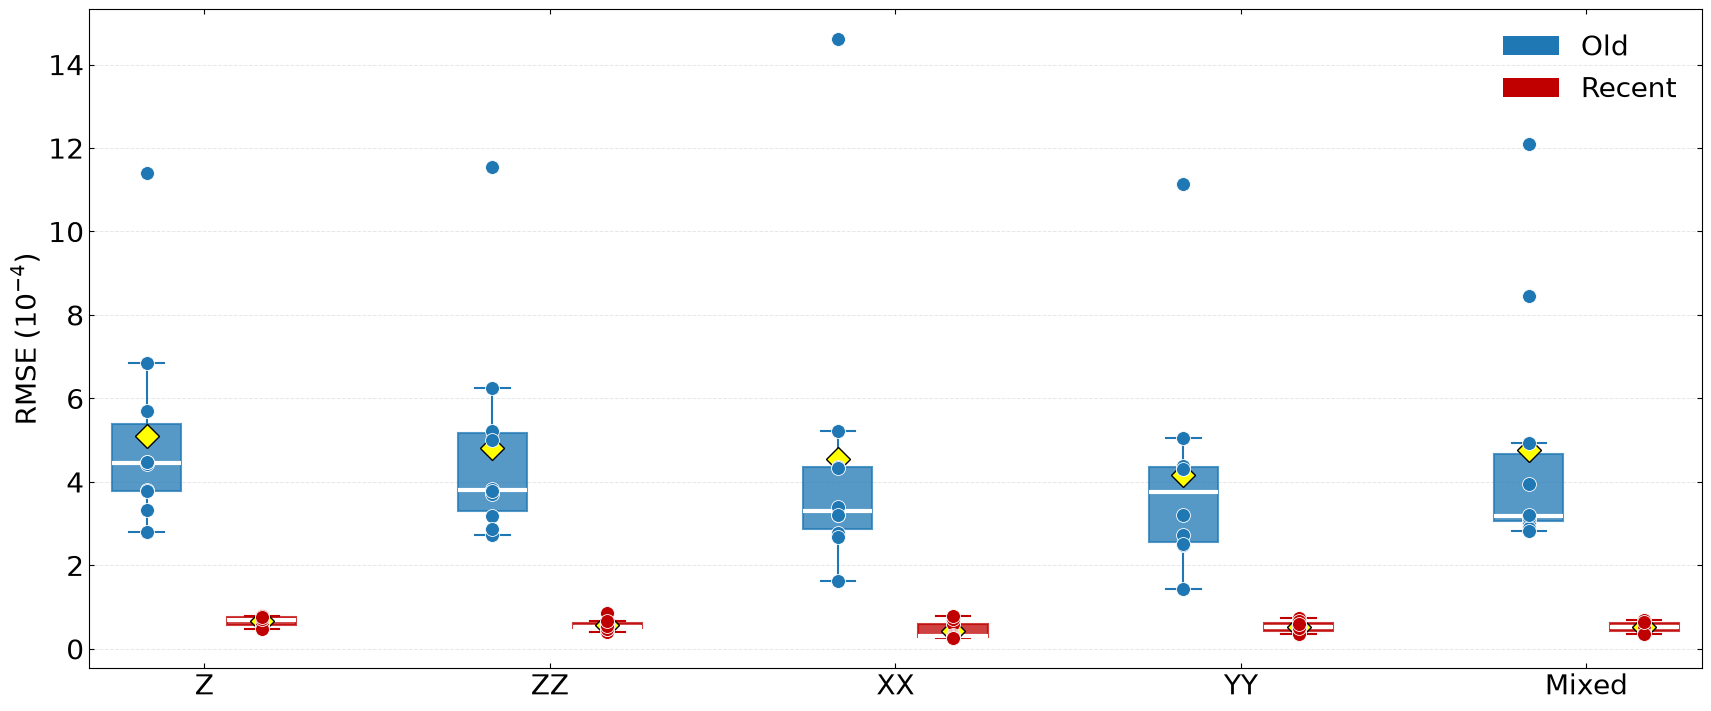

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==================================================
# 1. Caminhos
# ==================================================

BASE = Path("/home/camaral/inct_cq_hybrid_nn/runs/pinn")

PASTA_ANTIGA = BASE.parent / "mpc_product_2704/results/burgers"
PASTA_RECENTE = BASE / "mpc_serial"

observaveis = ["z", "zz", "xx", "yy", "mixed"]

# ==================================================
# 2. Carregar resultados das duas versões
# ==================================================

registros = []

for obs in observaveis:

    # Versão antiga
    arquivos = sorted(
        (PASTA_ANTIGA / f"mpc_product_{obs}").glob(
            "seed_*/metrics.json"
        )
    )

    for arquivo in arquivos:
        with open(arquivo) as f:
            m = json.load(f)

        registros.append({
            "versao": "Antiga",
            "observavel": obs.upper() if obs != "mixed" else "Mixed",
            "seed": int(arquivo.parent.name.split("_")[-1]),
            "rmse": m["rmse"],
            "parameters": m["parameters"]
        })

    # Versão recente
    arquivos = sorted(
        PASTA_RECENTE.glob(
            f"0*_*/q5_l3_{obs}_polynomial/seed_*/metrics.json"
        )
    )

    for arquivo in arquivos:
        with open(arquivo) as f:
            m = json.load(f)

        registros.append({
            "versao": "Recente",
            "observavel": obs.upper() if obs != "mixed" else "Mixed",
            "seed": int(arquivo.parent.name.split("_")[-1]),
            "rmse": m["rmse"],
            "parameters": m["parameters"]
        })

df_comparacao = pd.DataFrame(registros).drop_duplicates(
    subset=["versao", "observavel", "seed"]
)

# ==================================================
# 3. Resumo estatístico
# ==================================================

resumo = (
    df_comparacao.groupby(["observavel", "versao"])
    .agg(
        sementes=("seed", "nunique"),
        rmse_mean=("rmse", "mean"),
        rmse_median=("rmse", "median"),
        rmse_std=("rmse", "std"),
        parametros=("parameters", "first")
    )
    .reset_index()
)

display(
    resumo.style.format({
        "rmse_mean": "{:.6e}",
        "rmse_median": "{:.6e}",
        "rmse_std": "{:.6e}"
    })
)

# ==================================================
# 4. Boxplot
# ==================================================

fig, ax = plt.subplots(
    figsize=(17, 7),
    constrained_layout=True
)

cores = {
    "Antiga": "#1F77B4",
    "Recente": "#C00000"
}

posicoes = []
valores = []
cores_boxes = []

for i, obs in enumerate(observaveis):

    nome = obs.upper() if obs != "mixed" else "Mixed"

    for j, versao in enumerate(["Antiga", "Recente"]):

        posicoes.append(i * 3 + j + 1)

        valores.append(
            df_comparacao.loc[
                (df_comparacao["observavel"] == nome)
                & (df_comparacao["versao"] == versao),
                "rmse"
            ].to_numpy() * 1e4
        )

        cores_boxes.append(cores[versao])

bp = ax.boxplot(
    valores,
    positions=posicoes,
    widths=0.6,
    patch_artist=True,
    showfliers=False,
    showmeans=True,
    meanprops=dict(
        marker="D",
        markerfacecolor="yellow",
        markeredgecolor="black",
        markersize=12
    ),
    medianprops=dict(
        color="white",
        linewidth=3
    ),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5)
)

for i, cor in enumerate(cores_boxes):

    bp["boxes"][i].set(
        facecolor=cor,
        edgecolor=cor,
        alpha=0.75,
        linewidth=1.5
    )

    for elemento in [
        bp["whiskers"][2*i],
        bp["whiskers"][2*i+1],
        bp["caps"][2*i],
        bp["caps"][2*i+1]
    ]:
        elemento.set_color(cor)

    ax.scatter(
        np.full(len(valores[i]), posicoes[i]),
        valores[i],
        color=cor,
        edgecolor="white",
        linewidth=0.6,
        s=100,
        zorder=3
    )

# ==================================================
# 5. Estilo Mathematica
# ==================================================

centros = [
    i * 3 + 1.5
    for i in range(len(observaveis))
]

ax.set_xticks(centros)
ax.set_xticklabels(
    [o.upper() if o != "mixed" else "Mixed" for o in observaveis],
    fontsize=20
)

ax.set_ylabel(
    r"$\mathrm{RMSE}\;(10^{-4})$",
    fontsize=20
)

ax.tick_params(
    axis="both",
    which="both",
    direction="in",
    top=True,
    right=True,
    labelsize=20
)

ax.grid(
    True,
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.3
)

ax.set_axisbelow(True)

from matplotlib.patches import Patch

ax.legend(
    handles=[
        Patch(facecolor=cores["Antiga"], label="Old"),
        Patch(facecolor=cores["Recente"], label="Recent")
    ],
    fontsize=20,
    frameon=False
)

plt.show()

In [2]:
from pathlib import Path
import json
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ==================================================
# 1. Caminhos
# ==================================================

ROOT = Path("/home/camaral/inct_cq_hybrid_nn")

PASTA_ANTIGA = (
    ROOT / "runs/mpc_product_2704/results/burgers"
)

PASTA_RECENTE = (
    ROOT / "runs/pinn/mpc_serial/03_observables"
)

observaveis = ["z", "zz", "xx", "yy", "mixed"]

# ==================================================
# 2. Ler configurações e resultados
# ==================================================

registros = []
configuracoes = {}

for obs in observaveis:

    caminhos = {
        "Old": PASTA_ANTIGA / f"mpc_product_{obs}",
        "Recent": PASTA_RECENTE / f"q5_l3_{obs}_polynomial"
    }

    for versao, pasta in caminhos.items():

        for arquivo in sorted(pasta.glob("seed_*/metrics.json")):

            with open(arquivo) as f:
                m = json.load(f)

            seed = int(arquivo.parent.name.split("_")[-1])

            registros.append({
                "versao": versao,
                "observavel": obs.upper(),
                "seed": seed,
                "rmse": m["rmse"],
                "val_mse": m["best_val_mse"],
                "parameters": m["parameters"],
                "best_epoch": m["best_epoch"]
            })

            if (versao, obs) not in configuracoes:
                configuracoes[(versao, obs)] = m

df_auditoria = pd.DataFrame(registros)

# ==================================================
# 3. Resumo comparativo
# ==================================================

resumo_auditoria = (
    df_auditoria
    .groupby(["observavel", "versao"])
    .agg(
        sementes=("seed", "nunique"),
        rmse_mean=("rmse", "mean"),
        rmse_median=("rmse", "median"),
        rmse_std=("rmse", "std"),
        val_mean=("val_mse", "mean"),
        parameters=("parameters", "first"),
        best_epoch_mean=("best_epoch", "mean")
    )
    .reset_index()
)

display(
    resumo_auditoria.style.format({
        "rmse_mean": "{:.6e}",
        "rmse_median": "{:.6e}",
        "rmse_std": "{:.6e}",
        "val_mean": "{:.6e}",
        "best_epoch_mean": "{:.0f}"
    })
)

# ==================================================
# 4. Configuração antiga salva no YAML
# ==================================================

yaml_antigo = (
    ROOT
    / "runs/mpc_product_2704/config_mpc_product_z.yaml"
)

with open(yaml_antigo) as f:
    config_antiga = yaml.safe_load(f)

print("\n========== MODELO ANTIGO ==========")
print(yaml.safe_dump(
    config_antiga["models"][0],
    sort_keys=False
))

print("\n========== TREINAMENTO ANTIGO ==========")
print(yaml.safe_dump(
    config_antiga["training"],
    sort_keys=False
))

# ==================================================
# 5. Configurações registradas nos metrics.json
# ==================================================

for versao in ["Old", "Recent"]:

    m = configuracoes[(versao, "z")]

    print(f"\n========== {versao.upper()} ==========")

    print("Parâmetros:", m["parameters"])
    print("Best epoch:", m["best_epoch"])
    print("RMSE:", m["rmse"])

    print("Campos do metrics.json:")
    print(list(m.keys()))

    if "model_config" in m:
        print(json.dumps(
            m["model_config"],
            indent=2,
            ensure_ascii=False
        ))

,observavel,versao,sementes,rmse_mean,rmse_median,rmse_std,val_mean,parameters,best_epoch_mean
0,MIXED,Old,10,4.768606e-04,3.185048e-04,3.092380e-04,4.482469e-08,2403,14992
1,MIXED,Recent,10,5.170145e-05,5.174772e-05,1.171310e-05,2.604003e-09,3459,14915
2,XX,Old,10,4.541764e-04,3.306691e-04,3.678127e-04,3.052154e-08,2403,14996
3,XX,Recent,10,4.387674e-05,3.148046e-05,2.093579e-05,2.092227e-09,3459,14945
4,YY,Old,10,4.153742e-04,3.754239e-04,2.703048e-04,2.959780e-08,2403,14997
5,YY,Recent,10,5.293720e-05,5.235470e-05,1.265482e-05,3.036881e-09,3459,14618
6,Z,Old,10,5.105090e-04,4.455076e-04,2.495308e-04,1.623957e-07,2403,14992
7,Z,Recent,10,6.618231e-05,6.989094e-05,1.141433e-05,4.167013e-09,3459,14962
8,ZZ,Old,10,4.812176e-04,3.816082e-04,2.615340e-04,1.028936e-07,2403,14997
9,ZZ,Recent,10,5.714378e-05,5.350407e-05,1.298647e-05,3.023717e-09,3459,14970



========== MODELO ANTIGO ==========
name: mpc_product_z
kind: mpc_hybrid
width: 32
depth: 3
activation: tanh
qubits: 5
layers: 3
terms: 5
observables:
- ZIIII
- IZIII
- IIZII
- IIIZI
- IIIIZ
quantum_trainable: true
coupling: product
aggregation: mean


========== TREINAMENTO ANTIGO ==========
device: cpu
epochs: 15000
batch_size: 1000
lr: 0.005
scheduler: cosine
clip: null


========== OLD ==========
Parâmetros: 2403
Best epoch: 14998
RMSE: 0.00044287339551374316
Campos do metrics.json:
['problem', 'model', 'seed', 'device', 'parameters', 'time_s', 'best_epoch', 'best_val_mse', 'rmse', 'mae', 'relative_l2', 'max_abs_error', 'model_config', 'initial_coefficients', 'best_coefficients', 'final_coefficients']
{
  "name": "mpc_product_z",
  "kind": "mpc_hybrid",
  "width": 32,
  "depth": 3,
  "activation": "tanh",
  "qubits": 5,
  "layers": 3,
  "terms": 5,
  "observables": [
    "ZIIII",
    "IZIII",
    "IIZII",
    "IIIZI",
    "IIIIZ"
  ],
  "quantum_trainable": true,
  "coupling": "pr

In [3]:
import re

# ==================================================
# 1. Arquivos das duas implementações
# ==================================================

arquivos_codigo = {
    "OLD — Modelo": ROOT / "mpc/models.py",
    "OLD — Treinamento": ROOT / "mpc/train.py",
    "OLD — Job": ROOT / "job_mpc_product.pbs",
    "RECENT — Modelo e treinamento": ROOT / "pinn_mpc_serial.py"
}

# ==================================================
# 2. Termos de interesse
# ==================================================

padrao = re.compile(
    r"coupling|powers|exponents|cumprod|"
    r"observables|observable|pauli|"
    r"depth|width|layers|qubits|"
    r"normalize|bounds|"
    r"optimizer|adam|scheduler|"
    r"learning.rate|collocation|"
    r"n_ic|n_bc|epochs|"
    r"loss_pde|loss_ic|loss_bc|"
    r"cosine|seed",
    re.IGNORECASE
)

# ==================================================
# 3. Inspecionar os códigos
# ==================================================

def mostrar_trechos(caminho, contexto=2):

    linhas = caminho.read_text().splitlines()

    indices = set()

    for i, linha in enumerate(linhas):
        if padrao.search(linha):
            indices.update(
                range(
                    max(0, i - contexto),
                    min(len(linhas), i + contexto + 1)
                )
            )

    ultimo = -2

    for i in sorted(indices):

        if i > ultimo + 1:
            print("    ...")

        print(f"{i+1:4d} | {linhas[i]}")

        ultimo = i


for nome, caminho in arquivos_codigo.items():

    print("\n" + "=" * 70)
    print(nome)
    print("=" * 70)

    if caminho.exists():
        mostrar_trechos(caminho)
    else:
        print("Arquivo não encontrado:", caminho)


OLD — Modelo
    ...
   5 | 
   6 | 
   7 | def mlp(inputs, outputs, width, depth, activation="tanh"):
   8 |     """MLP com tanh por padrao; ultima camada linear."""
   9 |     layers = []
  10 |     for _ in range(depth):
  11 |         layers += [nn.Linear(inputs, width), nn.Tanh() if activation == "tanh" else nn.LeakyReLU(0.1)]
  12 |         inputs = width
  13 |     return nn.Sequential(*layers, nn.Linear(inputs, outputs))
  14 | 
  15 | 
  16 | PAULI = {
  17 |     "I": torch.eye(2, dtype=torch.complex64),
  18 |     "X": torch.tensor([[0, 1], [1, 0]], dtype=torch.complex64),
    ...
  22 | 
  23 | 
  24 | def pauli_matrix(word, qubits):
  25 |     """Observaveis como 'Z', 'XZ', 'ZYX', com uma letra por qubit."""
  26 |     if len(word) != qubits or any(p not in PAULI for p in word):
  27 |         raise ValueError(f"O observavel '{word}' deve ter {qubits} Pauli(s)")
  28 |     operator = PAULI[word[0]]
  29 |     for p in word[1:]:
  30 |         operator = torch.kron(operator

In [4]:
# ==================================================
# 1. Exemplo de coeficientes
# ==================================================

c = np.array([0.3, 0.6, 0.8, 0.5, 0.9])

# ==================================================
# 2. Bases de acoplamento
# ==================================================

polynomial = c ** np.arange(1, len(c) + 1)

product = np.cumprod(c)

linear = c.copy()

comparacao_bases = pd.DataFrame({
    "Termo": np.arange(1, len(c) + 1),
    "Coeficiente": c,
    "Polynomial": polynomial,
    "Product": product,
    "Sem potências": linear
})

display(comparacao_bases)

# ==================================================
# 3. Confirmar a expressão do código antigo
# ==================================================

codigo_antigo = (ROOT / "mpc/models.py").read_text()

print("Código antigo usa potências:",
      "z.pow(self.exponents)" in codigo_antigo)

print("Código antigo consulta coupling:",
      bool(re.search(
          r'cfg\.get\(["\']coupling["\']|cfg\[["\']coupling["\']',
          codigo_antigo
      )))

print("Código antigo implementa cumprod:",
      "cumprod" in codigo_antigo)

# Configuração efetiva registrada no job
print("\nConfiguração antiga:")
print("coupling =", config_antiga["models"][0].get("coupling"))
print("powers =", config_antiga["models"][0].get("powers", True))

,Termo,Coeficiente,Polynomial,Product,Sem potências
0,1,0.3,0.30000,0.3000,0.3
1,2,0.6,0.36000,0.1800,0.6
2,3,0.8,0.51200,0.1440,0.8
3,4,0.5,0.06250,0.0720,0.5
4,5,0.9,0.59049,0.0648,0.9


Código antigo usa potências: True
Código antigo consulta coupling: False
Código antigo implementa cumprod: False

Configuração antiga:
coupling = product
powers = True


,rmse_old,rmse_recent,ratio_median,ratio_mean,ratio_means
observavel,,,,,
Z,5.105090e-04,6.618231e-05,7.92,7.76,7.71
ZZ,4.812176e-04,5.714378e-05,7.75,8.17,8.42
XX,4.541764e-04,4.387674e-05,10.40,10.93,10.35
YY,4.153742e-04,5.293720e-05,6.30,8.50,7.85
MIXED,4.768606e-04,5.170145e-05,6.35,10.52,9.22


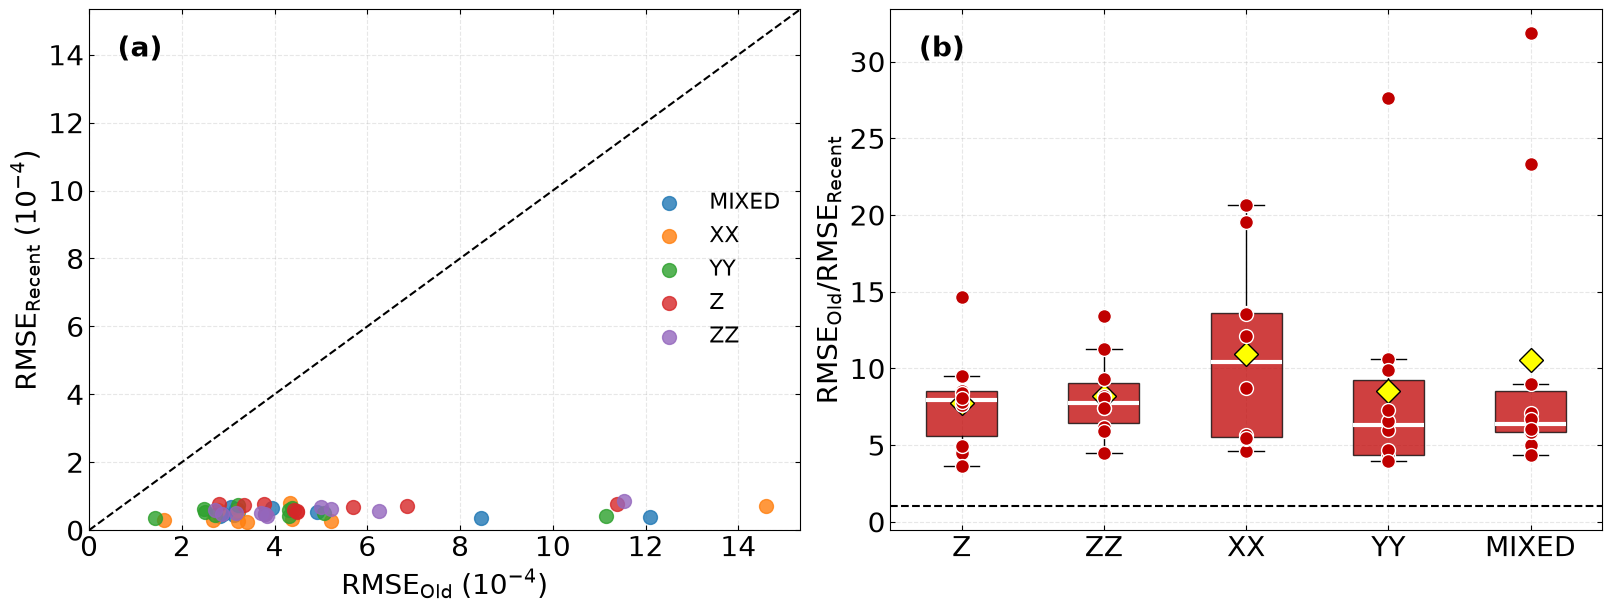

In [5]:
# ==================================================
# 1. Comparação pareada
# ==================================================

df_pareado = (
    df_auditoria.pivot_table(
        index=["observavel", "seed"],
        columns="versao",
        values="rmse"
    )
    .dropna()
    .reset_index()
)

df_pareado["ratio"] = (
    df_pareado["Old"] / df_pareado["Recent"]
)

# ==================================================
# 2. Resumo por observável
# ==================================================

resumo_pareado = (
    df_pareado.groupby("observavel")
    .agg(
        rmse_old=("Old", "mean"),
        rmse_recent=("Recent", "mean"),
        ratio_median=("ratio", "median"),
        ratio_mean=("ratio", "mean")
    )
    .reindex(["Z", "ZZ", "XX", "YY", "MIXED"])
)

resumo_pareado["ratio_means"] = (
    resumo_pareado["rmse_old"]
    / resumo_pareado["rmse_recent"]
)

display(
    resumo_pareado.style.format({
        "rmse_old": "{:.6e}",
        "rmse_recent": "{:.6e}",
        "ratio_median": "{:.2f}",
        "ratio_mean": "{:.2f}",
        "ratio_means": "{:.2f}"
    })
)

# ==================================================
# 3. Plot — Mesmas sementes em duas implementações
# ==================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6),
    constrained_layout=True
)

cores = {
    "Old": "#1F77B4",
    "Recent": "#C00000"
}

# ----------------------------------------------
# (a) RMSE antigo vs recente
# ----------------------------------------------

for obs, grupo in df_pareado.groupby("observavel"):

    axes[0].scatter(
        grupo["Old"] * 1e4,
        grupo["Recent"] * 1e4,
        s=100,
        alpha=0.8,
        label=obs
    )

limite = max(
    df_pareado["Old"].max(),
    df_pareado["Recent"].max()
) * 1e4 * 1.05

axes[0].plot(
    [0, limite],
    [0, limite],
    color="black",
    linestyle="--",
    linewidth=1.5
)

axes[0].set_xlim(0, limite)
axes[0].set_ylim(0, limite)

axes[0].set_xlabel(
    r"$\mathrm{RMSE}_{\mathrm{Old}}\;(10^{-4})$",
    fontsize=20
)

axes[0].set_ylabel(
    r"$\mathrm{RMSE}_{\mathrm{Recent}}\;(10^{-4})$",
    fontsize=20
)

axes[0].legend(fontsize=16, frameon=False)

# ----------------------------------------------
# (b) Razão por observável
# ----------------------------------------------

ordem = ["Z", "ZZ", "XX", "YY", "MIXED"]

dados_ratio = [
    df_pareado.loc[
        df_pareado["observavel"] == obs,
        "ratio"
    ].to_numpy()
    for obs in ordem
]

bp = axes[1].boxplot(
    dados_ratio,
    patch_artist=True,
    showfliers=False,
    showmeans=True,
    meanprops=dict(
        marker="D",
        markerfacecolor="yellow",
        markeredgecolor="black",
        markersize=12
    ),
    medianprops=dict(
        color="white",
        linewidth=3
    )
)

for caixa in bp["boxes"]:
    caixa.set(
        facecolor="#C00000",
        alpha=0.75
    )

for i, valores in enumerate(dados_ratio):

    axes[1].scatter(
        np.full(len(valores), i + 1),
        valores,
        color="#C00000",
        edgecolor="white",
        s=100,
        zorder=3
    )

axes[1].axhline(
    1,
    color="black",
    linestyle="--",
    linewidth=1.5
)

axes[1].set_xticks(range(1, len(ordem) + 1))
axes[1].set_xticklabels(ordem, fontsize=20)

axes[1].set_ylabel(
    r"$\mathrm{RMSE}_{\mathrm{Old}}/"
    r"\mathrm{RMSE}_{\mathrm{Recent}}$",
    fontsize=20
)

# ==================================================
# 4. Estilo Mathematica
# ==================================================

for ax, letra in zip(axes, ["(a)", "(b)"]):

    ax.text(
        0.04, 0.95,
        letra,
        transform=ax.transAxes,
        fontsize=20,
        fontweight="bold",
        va="top"
    )

    ax.tick_params(
        axis="both",
        which="both",
        direction="in",
        top=True,
        right=True,
        labelsize=20
    )

    ax.grid(
        True,
        linestyle="--",
        alpha=0.3
    )

    ax.set_axisbelow(True)

plt.show()